# SokoRadar EDA: nationwide, train 2006-2024
Scope: national monthly prices, trained on **2006-01 to 2024-12** (228 months). Test period: **2025-01 to 2026-09** (WFP only, untouched here).

**Evidence rule (group decision): estimated prices are *included and labelled*.** Nothing is thrown away silently. Every result that can depend on an estimated month is shown **twice, side by side**: once *including estimated months* (tag **[EST]**) and once on *real months only* (tag **[REAL]**). If the two agree, the finding does not depend on estimates. If they disagree, trust [REAL] and say so in the report.

**Evidence tiers (used everywhere).** A national price is *real* if it is
- **MoA observed:** Ministry of Agriculture daily prices with 10+ trading days in the month (2019-Feb 2022 only);
- **WFP scaled:** the median of 6 main WFP wholesale markets, rescaled to the MoA price level (all of 2006-2018 for maize, sorghum, beans, potatoes). Month-to-month movement is observed, the level is rescaled;
- **WFP direct:** a single WFP retail series (milk, vegetable oil).

*Thin* (MoA 1-9 days), *filled*, *interpolated*, *back-cast* and *proxy* months are **estimated**: they stay in the data, are shaded grey in the charts, and are counted in every [EST] result.

**County market prices (WFP) are always real**, whether the row is flagged `actual` or `aggregate` (see section 9 for what `aggregate` means and the sensitivity check).

Two data traps are handled explicitly: (1) the five bean varieties and the two potato types are **one price series times a constant** before 2019 (correlation 1.000), so each counts as ONE series; (2) milk and oil repeat the same value for months, so they fail a stale-value check.

In [3]:
import warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
warnings.filterwarnings('ignore')

# ---- where the data lives ----
XNAME = 'SokoRadar_County_2006_2024.xlsx'
here = Path.cwd()
ROOT = next((p for p in [here, *here.parents] if (p / 'output' / XNAME).exists()), None)
if ROOT is not None:                                   # repo layout (data not in git)
    XLSX = ROOT / 'output' / XNAME
    DATA = ROOT / 'sokoradar_raw_data'                 # national drivers, WFP, counties, climate, geojson
    OUT_DIR = ROOT / 'output' / 'modelling'
else:                                                  # flat folder, e.g. CAPSTONE2: everything next to the notebook
    ROOT = next((p for p in [here, *here.parents] if (p / XNAME).exists()), None)
    assert ROOT is not None, f'Could not find {XNAME} in {here} or any parent folder.'
    XLSX = ROOT / XNAME
    DATA = ROOT
    OUT_DIR = ROOT

HANDOFF = OUT_DIR / 'handoff'; FIG = OUT_DIR / 'figures'
HANDOFF.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

# ---- the agreed plan (see the decision log below) ----
TRAIN = ('2006-01','2024-12'); TEST = ('2025-01','2026-09')
INCLUDE_AGGREGATE = True      # WFP priceflag "aggregate" rows are kept (flagged). False = actual-only sensitivity run
rng = np.random.default_rng(42)
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.25})

_need = [XLSX] + [DATA/f for f in ('wfp_food_prices_ken.csv','national_drivers_2006_2024.csv','counties.csv','county_climate_chirps_ndvi.csv')]
_missing = [str(p) for p in _need if not p.exists()]
assert not _missing, 'Missing data files: ' + ', '.join(_missing)
print('ROOT =', ROOT, '| DATA =', DATA)

ROOT = C:\Users\dwtha\CAPSTONE2 | DATA = C:\Users\dwtha\CAPSTONE2


## Decision Log

| # | Decision | Why | Check / cost |
|---|---|---|---|
| D1 | **Train 2006-01 to 2024-12, test 2025-01 to 2026-09 (WFP only).** | 19 training years: more drought and price-shock episodes (2008-09, 2011, 2017, 2022), tighter seasonal intervals, and it is what the group agreed. | 2006-2018 national staple prices are *WFP-scaled* (movement observed, level rescaled), 2019-Feb 2022 is MoA. Notebook 02 includes a **2006 vs 2019 training-start sensitivity** on the same test cuts, so the choice can be revisited with numbers. In the delivered run, training from 2006 was as good or better than from 2019 at all three horizons (only 7 test cuts, so treat it as "no evidence that 2019 is better", not proof). |
| D2 | **Estimated prices are included and labelled; every affected result is shown [EST] next to [REAL].** | The group wanted nothing silently dropped. | Where the two versions disagree, the report quotes [REAL] and says so. |
| D3 | **WFP `aggregate` rows are real market data and are included**, with a `flag` column kept. | They are monthly values built from several price collections. Only 3 flag values exist: `actual`, `aggregate`, `actual,aggregate`. | I could not find a first-party WFP definition on the pages reachable from here (see section 9), so section 9 shows **actual-only vs actual+aggregate** side by side and `INCLUDE_AGGREGATE` flips it. Worth confirming with WFP / the HDX dataset page. |
| D4 | **Five bean varieties and two potato types count as one series each** before 2019. | Correlation 1.000 on 2006-2018 changes: one price times a constant. | Rule: corr of monthly log changes > 0.995 on 2006-2018. |
| D5 | **Series must be at least 35% real and at most 10% flat months** to enter the modelling set. | Keeps back-cast and stale series out of *model fitting* (they remain visible and labelled). | Eggs fall out in the 2006 window (see section 3b). |
| D6 | **All WFP weight units are converted to KES/kg** (`KG`, `50 KG`, `64 KG`, `90 KG`, `100 KG`, decimals). | A regex replaces a 4-entry lookup. | The "64 KG" rows turned out to be tomatoes, which are not in the staples ledger (section 9). |

## 1. Load national prices and how each month was obtained

In [4]:
raw = pd.read_excel(XLSX, 'National_Prices', header=None, skiprows=4)
hdr = pd.read_excel(XLSX, 'National_Prices', header=None, skiprows=3, nrows=1).iloc[0].tolist()
vals = [c for c in range(1,18)]
names = [str(hdr[c]).replace(' (KES/kg)','').replace(' (KES/L)','') for c in vals]
P = raw[[0]+vals].copy(); P.columns = ['month']+names
M = raw[[0]+list(range(19,36))].copy(); M.columns = ['month']+names
for d in (P,M): d['month'] = pd.to_datetime(d['month']).dt.to_period('M')
P = P.set_index('month').astype(float); M = M.set_index('month')

def kind(s):
    s = str(s)
    if s.startswith('Observed'): return 'MoA observed'
    if s.startswith('Thin'): return 'Thin'
    if s.startswith('WFP wholesale scaled'): return 'WFP scaled'
    if s.startswith('WFP Nairobi retail') or s.startswith('WFP retail'): return 'WFP direct'
    if s.startswith('Filled') or s.startswith('Interpol'): return 'Filled'
    if s.startswith('Back-cast') or s.startswith('Proxy') or s.startswith('WFP'): return 'Back-cast/proxy'
    return 'Other'
K = M.apply(lambda s: s.map(kind))
REAL_MOA = K.eq('MoA observed')                                  # strict MoA only
REAL = K.isin(['MoA observed','WFP scaled','WFP direct'])        # real for modelling (see evidence tiers above)
THIN = K.eq('Thin')
tr = slice(pd.Period(TRAIN[0]), pd.Period(TRAIN[1]))
print(P.loc[tr].shape, 'train months x commodities')
print(K.loc[tr].stack().value_counts())

(228, 17) train months x commodities
WFP scaled         1402
Back-cast/proxy    1161
Filled              362
WFP direct          356
MoA observed        344
Thin                183
Other                68
Name: count, dtype: int64


## 2. Provenance audit (the main finding): how much of 2006-2024 is real, and of what kind?

,real share,MoA-only share,flat-month share,Back-cast/proxy,Filled,MoA observed,Other,Thin,WFP direct,WFP scaled
Dry Maize,0.82,0.14,0.00,0.00,0.10,0.14,0.00,0.08,0.00,0.68
Beans Mwitemania,0.82,0.14,0.00,0.00,0.10,0.14,0.00,0.08,0.00,0.68
White Irish Potatoes,0.82,0.14,0.00,0.00,0.10,0.14,0.00,0.08,0.00,0.68
Red Irish Potatoes,0.82,0.14,0.00,0.00,0.10,0.14,0.00,0.08,0.00,0.68
Sorghum,0.82,0.14,0.03,0.00,0.10,0.14,0.00,0.08,0.00,0.68
Mwezi Moja,0.82,0.14,0.00,0.00,0.10,0.14,0.00,0.08,0.00,0.68
Beans Dolichos (Njahi),0.82,0.14,0.00,0.00,0.10,0.14,0.00,0.08,0.00,0.68
Beans Rosecoco,0.82,0.14,0.00,0.00,0.10,0.14,0.00,0.08,0.00,0.68
Beans Canadian,0.82,0.14,0.00,0.00,0.10,0.14,0.00,0.08,0.00,0.68
Milk (pasteurized),0.78,0.00,0.43,0.00,0.09,0.00,0.13,0.00,0.78,0.00


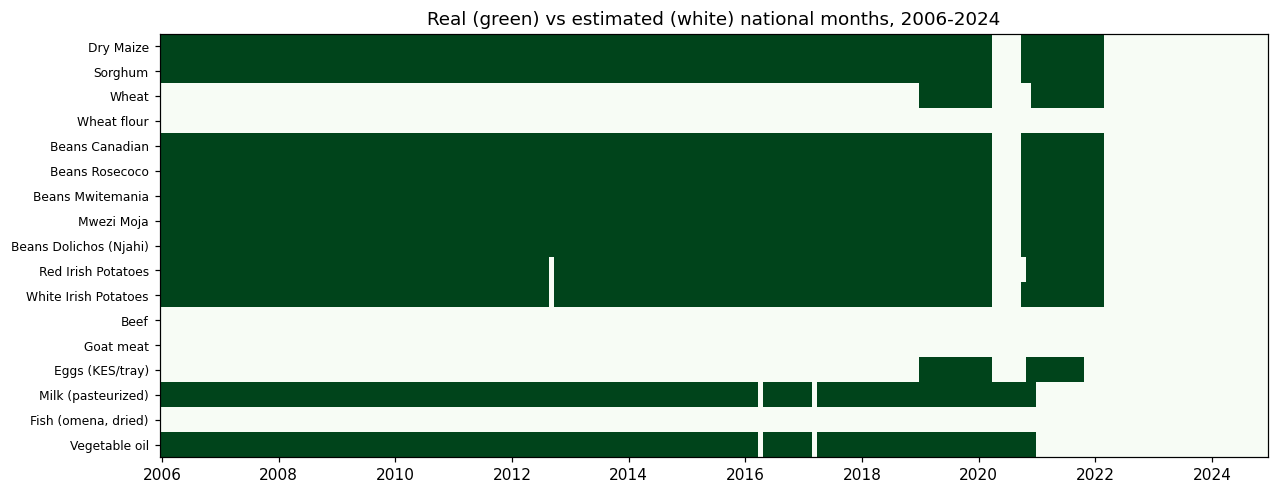

month,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Dry Maize,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.00,1.00,1.0,1.0,0.50,1.00,0.17,0.0,0.0
Sorghum,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.00,1.00,1.0,1.0,0.50,1.00,0.17,0.0,0.0
Wheat,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.00,0.00,0.0,1.0,0.33,1.00,0.17,0.0,0.0
Wheat flour,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.00,0.00,0.00,0.0,0.0
Beans Canadian,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.00,1.00,1.0,1.0,0.50,1.00,0.17,0.0,0.0
Beans Rosecoco,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.00,1.00,1.0,1.0,0.50,1.00,0.17,0.0,0.0
Beans Mwitemania,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.00,1.00,1.0,1.0,0.50,1.00,0.17,0.0,0.0
Mwezi Moja,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.00,1.00,1.0,1.0,0.50,1.00,0.17,0.0,0.0
Beans Dolichos (Njahi),1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0,1.0,1.00,1.00,1.0,1.0,0.50,1.00,0.17,0.0,0.0
Red Irish Potatoes,1.0,1.0,1.0,1.0,1.0,1.0,0.92,1.0,1.0,1.0,1.00,1.00,1.0,1.0,0.42,1.00,0.17,0.0,0.0


In [5]:
share = REAL.loc[tr].mean().rename('real share')
share_moa = REAL_MOA.loc[tr].mean().rename('MoA-only share')
flat = (P.loc[tr].diff()==0).mean().rename('flat-month share')       # same value as the month before = stale
mix = K.loc[tr].apply(lambda s: s.value_counts(normalize=True)).T.fillna(0).round(2)
audit = pd.concat([share.round(2), share_moa.round(2), flat.round(2), mix], axis=1).sort_values('real share', ascending=False)
display(audit)
fig,ax=plt.subplots(figsize=(13,5))
ax.imshow(REAL.loc[tr].T.values.astype(float),aspect='auto',cmap='Greens',interpolation='nearest')
ax.set_yticks(range(len(names))); ax.set_yticklabels(names,fontsize=8)
idx=REAL.loc[tr].index; ticks=[i for i,p in enumerate(idx) if p.month==1 and p.year%2==0]
ax.set_xticks(ticks); ax.set_xticklabels([idx[i].year for i in ticks]); ax.grid(False)
ax.set_title('Real (green) vs estimated (white) national months, 2006-2024'); plt.show()
by_year = REAL.loc[tr].groupby(REAL.loc[tr].index.year).mean().round(2); display(by_year.T)

**What it shows:** Which national months are real (green) and which are estimated (white), for every commodity.

**Insight:** Maize, sorghum, beans and potatoes are real almost all the way from 2006 to early 2022. After that the whole national row turns white. Beef, goat meat, fish and wheat flour are never real, and milk and vegetable oil stop in 2021.

**What it means for SokoRadar:** Only the four core crops are strong enough to train models on. Everything after early 2022 at national level is an estimate, so it should not be used to judge a model.

**Read this first.** Maize, sorghum, beans and potatoes are real for most of 2006-2018 (WFP-scaled) and 2019-Feb 2022 (MoA-observed), and **estimated afterwards**. Wheat, wheat flour, beef, goat meat, eggs and fish are back-cast or proxied; milk and oil are real WFP series but repeat the same value for months.

**Important for 2023-24:** the national reference prices for 2023-24 are entirely estimated (the MoA feed stops in early 2022). That says nothing about WFP county markets, which **do still report real prices in 2023-24**; section 9 counts them. The next cell turns these rules into the modelling set.

In [6]:
MIN_REAL, MAX_FLAT = 0.35, 0.10
CAND = [c for c in audit.index if audit.loc[c,'real share'] >= MIN_REAL and audit.loc[c,'flat-month share'] <= MAX_FLAT]
# collapse perfect duplicates: varieties that are one price times a constant in the WFP-scaled years (2006-2018), corr of log changes > 0.995
Lc = np.log(P.loc[:'2018-12', CAND]).diff()
order = [c for c in ['Dry Maize','Sorghum','Beans Rosecoco','Red Irish Potatoes'] if c in CAND] + [c for c in CAND if c not in ('Dry Maize','Sorghum','Beans Rosecoco','Red Irish Potatoes')]
CORE, DUPES = [], {}
for c in order:
    twin = next((k for k in CORE if Lc[c].corr(Lc[k]) > 0.995), None)
    if twin: DUPES[c] = twin
    else: CORE.append(c)
print('Candidates (real share >= %.0f%% and flat months <= %.0f%%):' % (MIN_REAL*100, MAX_FLAT*100), CAND)
print('Duplicates collapsed (same series x constant):', DUPES)
print('INDEPENDENT modelling set (CORE):', CORE)
print('Excluded:', [c for c in names if c not in CAND])
for c in names:
    if c not in CAND: print('  -', c, '| real', audit.loc[c,'real share'], '| flat', audit.loc[c,'flat-month share'])

Candidates (real share >= 35% and flat months <= 10%): ['Dry Maize', 'Beans Mwitemania', 'White Irish Potatoes', 'Red Irish Potatoes', 'Sorghum', 'Mwezi Moja', 'Beans Dolichos (Njahi)', 'Beans Rosecoco', 'Beans Canadian']
Duplicates collapsed (same series x constant): {'Beans Mwitemania': 'Beans Rosecoco', 'White Irish Potatoes': 'Red Irish Potatoes', 'Mwezi Moja': 'Beans Rosecoco', 'Beans Dolichos (Njahi)': 'Beans Rosecoco', 'Beans Canadian': 'Beans Rosecoco'}
INDEPENDENT modelling set (CORE): ['Dry Maize', 'Sorghum', 'Beans Rosecoco', 'Red Irish Potatoes']
Excluded: ['Wheat', 'Wheat flour', 'Beef', 'Goat meat', 'Eggs (KES/tray)', 'Milk (pasteurized)', 'Fish (omena, dried)', 'Vegetable oil']
  - Wheat | real 0.13 | flat 0.0
  - Wheat flour | real 0.0 | flat 0.0
  - Beef | real 0.0 | flat 0.05
  - Goat meat | real 0.0 | flat 0.01
  - Eggs (KES/tray) | real 0.12 | flat 0.0
  - Milk (pasteurized) | real 0.78 | flat 0.43
  - Fish (omena, dried) | real 0.0 | flat 0.0
  - Vegetable oil | re

### 3b. Second look at eggs
Eggs were borderline in the earlier 2019-2024 version (about 38% real, only just above the 35% cut-off). In the 2006-2024 window the picture is clearer: before 2019 eggs are a back-cast, so the real share collapses. The cell below shows the numbers for both windows and the tier mix. **Eggs stay in the data and in every chart, labelled as estimated, but they are not used to fit models.**

In [7]:
egg = [c for c in names if 'egg' in c.lower()]
for c in egg:
    for lab, a, b in (('2006-2024 (agreed train window)', '2006-01', '2024-12'), ('2019-2024 (earlier window)', '2019-01', '2024-12')):
        w = slice(pd.Period(a), pd.Period(b))
        print(f'{c:<28} {lab:<34} real share {REAL.loc[w, c].mean():.0%} | MoA-only {REAL_MOA.loc[w, c].mean():.0%} | flat months {(P.loc[w, c].diff()==0).mean():.0%}')
    print('  tier mix 2006-2024:', K.loc[tr, c].value_counts(normalize=True).round(2).to_dict())
    print('  in modelling set (>= %.0f%% real, <= %.0f%% flat)?' % (MIN_REAL*100, MAX_FLAT*100), c in CAND, '-> kept as an [EST] series only' if c not in CAND else '')
print('Note: the 35% cut-off was set so that eggs just passed in the 2019-2024 window. Over 2006-2024 the cut-off is no longer borderline for eggs, so it can stay at 35%.')

Eggs (KES/tray)              2006-2024 (agreed train window)    real share 12% | MoA-only 12% | flat months 0%
Eggs (KES/tray)              2019-2024 (earlier window)         real share 38% | MoA-only 38% | flat months 0%
  tier mix 2006-2024: {'Back-cast/proxy': 0.68, 'Filled': 0.19, 'MoA observed': 0.12, 'Thin': 0.01}
  in modelling set (>= 35% real, <= 10% flat)? False -> kept as an [EST] series only
Note: the 35% cut-off was set so that eggs just passed in the 2019-2024 window. Over 2006-2024 the cut-off is no longer borderline for eggs, so it can stay at 35%.


## 3. Coverage: real months by block, and where MoA data actually exists

In [8]:
def blocks_of(mask):
    out=[]; start=None
    for p,v in mask.items():
        if v and start is None: start=p
        if (not v) and start is not None: out.append((start,p-1)); start=None
    if start is not None: out.append((start,mask.index[-1]))
    return out
r = REAL.loc[tr, CORE].any(axis=1); rm = REAL_MOA.loc[tr, CORE].any(axis=1)
print('Real blocks (WFP scaled + MoA observed), any core series:'); [print(' ',a,'->',b,'(',(b-a).n+1,'months)') for a,b in blocks_of(r)]
print('MoA-observed blocks only:'); [print(' ',a,'->',b,'(',(b-a).n+1,'months)') for a,b in blocks_of(rm)]
print('Months with no real core price:', int((~r).sum()),'of',len(r), '| months with MoA-observed price:', int(rm.sum()))

Real blocks (WFP scaled + MoA observed), any core series:
  2006-01 -> 2020-03 ( 171 months)
  2020-10 -> 2022-02 ( 17 months)
MoA-observed blocks only:
  2019-01 -> 2020-03 ( 15 months)
  2020-10 -> 2022-02 ( 17 months)
Months with no real core price: 40 of 228 | months with MoA-observed price: 32


## 4. Price behaviour, 2006-2024 (real months marked)

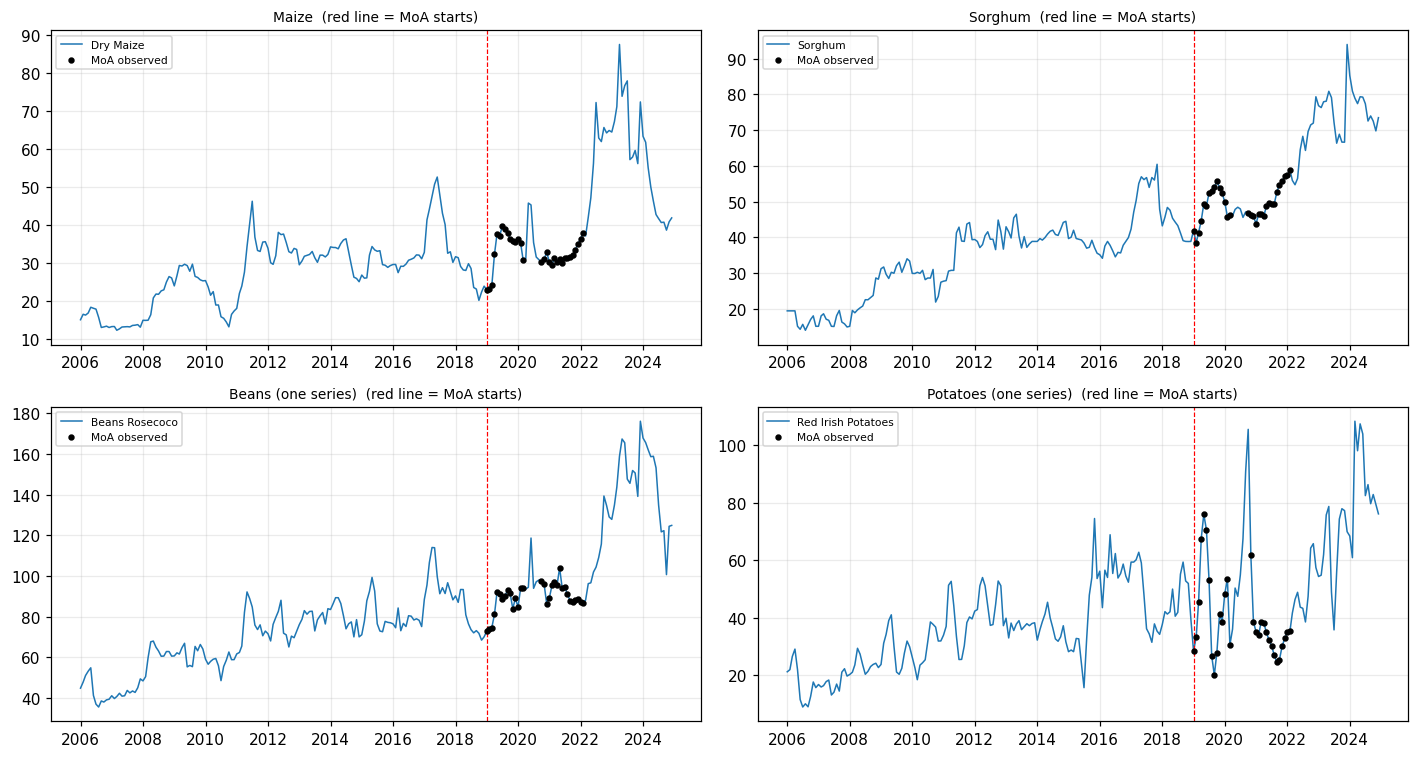

In [9]:
grp = {'Maize':['Dry Maize'],'Sorghum':['Sorghum'],'Beans (one series)':[c for c in CORE if 'Bean' in c or c=='Mwezi Moja'],'Potatoes (one series)':[c for c in CORE if 'Potato' in c]}
fig,axs=plt.subplots(2,2,figsize=(13,7))
for ax,(g,cs) in zip(axs.ravel(),grp.items()):
    for c in cs:
        s=P.loc[tr,c]; ax.plot(s.index.to_timestamp(),s.values,lw=1,label=c)
        rr=REAL_MOA.loc[tr,c]; ax.scatter(s.index[rr].to_timestamp(),s[rr],s=10,c='k',zorder=3,label='MoA observed')
    ax.axvline(pd.Timestamp('2019-01-01'),c='r',ls='--',lw=.8); ax.set_title(g+'  (red line = MoA starts)',fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**What it shows:** The four core national prices from 2006 to 2024. Black dots are months the Ministry of Agriculture actually observed; the red line marks where Ministry data starts (2019).

**Insight:** Ministry data covers only a short window (2019 to early 2022). The biggest moves in the chart, the 2022 to 2023 surge in maize, beans and sorghum, sit after the dots stop, so they are estimates. Potatoes are clearly the most jumpy series.

**What it means for SokoRadar:** The most dramatic price spike on the national chart cannot be used as proof that the model works, because nobody observed it at national level.

## 5. How hard is 'same as last month'? Month-on-month size and autocorrelation

In [10]:
L = np.log(P.loc[tr, CORE]); R = L.diff()
PAIR = REAL.loc[tr, CORE] & REAL.loc[tr, CORE].shift(1, fill_value=False)
Rr = R.where(PAIR)            # month-on-month change only when BOTH months are real
def rowstats(c):
    r=R[c].dropna(); both=(REAL.loc[tr,c]&REAL.loc[tr,c].shift(1,fill_value=False)).reindex(r.index)
    return pd.Series({'median |MoM| %':100*np.expm1(r.abs().median()),'p90 |MoM| %':100*np.expm1(r.abs().quantile(.9)),
        'sd MoM %':100*r.std(),'ACF lag1':r.autocorr(1),'ACF lag12':r.autocorr(12),
        'real pairs':int(both.sum()),'% pairs with an estimated month':100*(1-both.mean()),'median |MoM| % (real pairs)':100*np.expm1(r[both].abs().median()) if both.sum()>3 else np.nan})
display(pd.DataFrame({c:rowstats(c) for c in CORE}).T.round(2))

,median |MoM| %,p90 |MoM| %,sd MoM %,ACF lag1,ACF lag12,real pairs,% pairs with an estimated month,median |MoM| % (real pairs)
Dry Maize,3.97,17.04,9.10,0.18,0.07,186.0,18.06,3.73
Sorghum,3.45,11.36,7.73,-0.06,0.03,186.0,18.06,3.74
Beans Rosecoco,3.91,12.95,7.56,-0.01,0.06,186.0,18.06,3.88
Red Irish Potatoes,11.31,38.14,19.65,0.20,-0.02,183.0,19.38,10.30


In [11]:
# Naive / seasonal-naive log-MAE at horizons 1,2,3.
# Columns WITHOUT a suffix = [EST] all months (estimated months included). Columns "(real ends)" = [REAL] both ends real.
def naive_err(c,h,real_only=False):
    s=L[c]; e=(s.shift(-h)-s).abs()
    if real_only: ok=REAL.loc[tr,c]&REAL.loc[tr,c].shift(-h,fill_value=False); e=e[ok]
    return e.mean()
def snaive_err(c,h,real_only=False):
    s=L[c]; e=(s.shift(-h)-s.shift(12-h)).abs()
    if real_only:
        rl=REAL.loc[tr,c]; ok=rl & rl.shift(-h,fill_value=False) & rl.shift(12-h,fill_value=False); e=e[ok]
    return e.mean()
rows=[]
for c in CORE:
    rows.append({'commodity':c,**{f'naive h{h}':naive_err(c,h) for h in (1,2,3)},
      **{f'naive h{h} (real ends)':naive_err(c,h,True) for h in (1,2,3)},
      **{f'seasonal h{h}':snaive_err(c,h) for h in (1,2,3)},
      **{f'seasonal h{h} (real ends)':snaive_err(c,h,True) for h in (1,2,3)}})
B=pd.DataFrame(rows).set_index('commodity').round(3); display(B)
share_est = {c: 1-REAL.loc[tr,c].mean() for c in CORE}
print('Share of months that are ESTIMATED in the [EST] columns:', {k: f'{v:.0%}' for k,v in share_est.items()})
print('Target check: a model must cut the naive error by 10% => naive h3 x 0.9 =')
display((B['naive h3']*0.9).round(3))
print('Baselines on the real-only basis are the fair bar for a model. If [EST] and [REAL] differ a lot, estimated months are smoothing the series (interpolation makes "same as last month" look too good).')

,naive h1,naive h2,naive h3,naive h1 (real ends),naive h2 (real ends),naive h3 (real ends),seasonal h1,seasonal h2,seasonal h3,seasonal h1 (real ends),seasonal h2 (real ends),seasonal h3 (real ends)
commodity,,,,,,,,,,,,
Dry Maize,0.062,0.101,0.130,0.056,0.092,0.121,0.285,0.285,0.285,0.268,0.269,0.270
Sorghum,0.052,0.079,0.092,0.054,0.082,0.095,0.171,0.171,0.171,0.180,0.181,0.181
Beans Rosecoco,0.054,0.080,0.099,0.052,0.076,0.096,0.161,0.161,0.161,0.149,0.149,0.150
Red Irish Potatoes,0.144,0.224,0.271,0.141,0.215,0.263,0.350,0.350,0.350,0.317,0.319,0.320


Share of months that are ESTIMATED in the [EST] columns: {'Dry Maize': '18%', 'Sorghum': '18%', 'Beans Rosecoco': '18%', 'Red Irish Potatoes': '18%'}
Target check: a model must cut the naive error by 10% => naive h3 x 0.9 =


commodity
Dry Maize             0.117
Sorghum               0.083
Beans Rosecoco        0.089
Red Irish Potatoes    0.244
Name: naive h3, dtype: float64

Baselines on the real-only basis are the fair bar for a model. If [EST] and [REAL] differ a lot, estimated months are smoothing the series (interpolation makes "same as last month" look too good).


**How to read the table above.** Columns without a suffix are **[EST]**: they include estimated months. Columns marked `(real ends)` are **[REAL]**: both the forecast origin and the target month are real. Compare them: interpolated or filled months are smooth, so [EST] errors can look better than they really are.
**Insight to state in the report:** compare `naive` with `seasonal` on the real-ends columns. If seasonal-naive is worse than naive, beating seasonal-naive is nearly free; score with MASE scaled by the naive forecast, and treat the 10% target as a stretch goal at 2-3 months.

## 6. Seasonality with confidence intervals (bootstrap over years, real months only)

Dry Maize months whose CI excludes 0: [5, 6, 7]
Sorghum months whose CI excludes 0: []


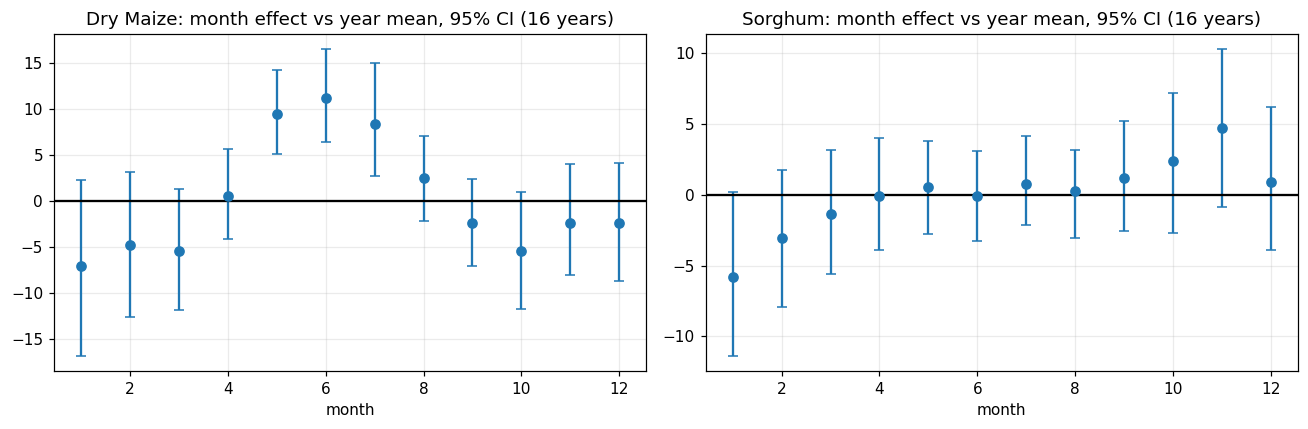

In [12]:
def s_years(c):
    rl=REAL.loc[tr,c]; yrs=rl.groupby(rl.index.year).mean(); return list(yrs[yrs>=.5].index)
def seas(c):
    s=np.log(P.loc[tr,c]); dev=s-s.groupby(s.index.year).transform('mean')   # within-year deviation
    full=REAL.loc[tr,c].groupby(REAL.loc[tr,c].index.year).transform('mean')>=0.5
    d=dev[full]; yrs=sorted(set(d.index.year)); 
    if len(yrs)<3: return None
    obs=d.groupby(d.index.month).mean()
    bs=[]
    for _ in range(2000):
        pick=rng.choice(yrs,len(yrs)); x=pd.concat([d[d.index.year==y] for y in pick])
        bs.append(x.groupby(x.index.month).mean())
    bs=pd.DataFrame(bs); return pd.DataFrame({'effect %':100*np.expm1(obs),'lo':100*np.expm1(bs.quantile(.025)),'hi':100*np.expm1(bs.quantile(.975))})
fig,axs=plt.subplots(1,2,figsize=(12,4))
for ax,c in zip(axs,['Dry Maize','Sorghum']):
    if c not in CORE: continue
    t=seas(c)
    if t is None: ax.set_title(c+': too few years'); continue
    ax.errorbar(t.index,t['effect %'],yerr=[t['effect %']-t['lo'],t['hi']-t['effect %']],fmt='o',capsize=3)
    ax.axhline(0,c='k'); ax.set_title(f'{c}: month effect vs year mean, 95% CI ({len(s_years(c))} years)'); ax.set_xlabel('month')
    print(c,'months whose CI excludes 0:',list(t.index[(t.lo>0)|(t.hi<0)]))
plt.tight_layout(); plt.show()

**What it shows:** For each calendar month, how far maize and sorghum prices sit above or below their yearly average, with a 95% range built from real years only.

**Insight:** Maize is clearly dearer in May, June and July (about 8 to 11% above the yearly average), and the range for those months stays above zero. This is the lean season before the main harvest. Sorghum shows no month that is clearly different.

**What it means for SokoRadar:** A seasonal feature is worth adding for maize but not for sorghum. An alert in May to July should be compared with the normal seasonal rise, so we do not flag the usual lean season as a crisis.

Keep a seasonal claim only for months whose interval excludes 0. About 16-17 years qualify (>=50% real months), so the intervals are tighter than a 2019-2024 window would give; remember that 2006-2018 values are WFP-scaled.

## 7. Drivers: do rainfall, FX, fuel and inflation lead price changes? (national, 2006-2024, real consecutive months only)

**[EST] vs [REAL].** Each regression is run twice: **[EST]** on every month-on-month change (includes estimated months, mostly 2022-2024), and **[REAL]** only when *both* months are real. The comparison table puts them side by side. A driver result is only trustworthy if it keeps its sign and strength on [REAL].

In [13]:
D = pd.read_csv(DATA/'national_drivers_2006_2024.csv'); D['Month']=pd.to_datetime(D['Month']).dt.to_period('M'); D=D.set_index('Month')
cols = {'Rain 3m % normal':'Rainfall last 3 months, % of normal','KES per USD':'KES per USD','Diesel':'Diesel (KES/L)',
        'Food inflation':'Food inflation (%)','NDVI % normal':'Vegetation, % of normal'}
X = pd.DataFrame({k:D[v] for k,v in cols.items()}).loc[tr]
dX = X.copy(); dX['KES per USD']=np.log(X['KES per USD']).diff(); dX['Diesel']=np.log(X['Diesel']).diff()
import statsmodels.api as sm
def run_drivers(Y, basis):
    out=[]
    for c in CORE:
        y=Y[c]
        for k in dX.columns:
            for lag in (1,2,3):
                d=pd.concat([y,dX[k].shift(lag)],axis=1).dropna(); d.columns=['y','x']
                if len(d)<30: continue
                m=sm.OLS(d.y,sm.add_constant(d.x)).fit(cov_type='HAC',cov_kwds={'maxlags':3})
                out.append({'commodity':c,'driver':k,'lag':lag,'corr':d.corr().iloc[0,1],'t':m.tvalues['x'],'p':m.pvalues['x'],'n':len(d)})
    r=pd.DataFrame(out).sort_values('p').reset_index(drop=True); m_=len(r)
    r['p_holm']=np.minimum(1,(r.p*(m_-r.index)).cummax()); r['basis']=basis; return r
res_est  = run_drivers(R,  '[EST] incl. estimated')      # all month-on-month changes
res_real = run_drivers(Rr, '[REAL] real pairs only')     # both months real
res = res_real                                           # kept for the findings cell
for r_ in (res_est, res_real):
    print('\n===', r_.basis.iloc[0], '| top 10 by p | survive Holm at 5%:', int((r_.p_holm<.05).sum()), 'of', len(r_))
    display(r_.head(10).drop(columns='basis').round(3))
key=['commodity','driver','lag']
cmp_=res_est.merge(res_real,on=key,suffixes=('_est','_real'),how='outer')
cmp_['same_sign']=np.sign(cmp_.t_est)==np.sign(cmp_.t_real)
cmp_['min_p']=cmp_[['p_est','p_real']].min(axis=1)
print('\n=== Side by side: [EST] vs [REAL] for the 15 strongest driver tests ===')
display(cmp_.sort_values('min_p').head(15)[key+['t_est','p_est','n_est','t_real','p_real','n_real','same_sign']].round(3))
print('Tests with p<0.05 on [EST]:', int((res_est.p<.05).sum()), '| on [REAL]:', int((res_real.p<.05).sum()), '| of', len(res_real), f'(about {round(.05*len(res_real))} expected by chance)')
print('Of the [EST] p<0.05 tests, how many keep p<0.05 on [REAL]:', int(((cmp_.p_est<.05)&(cmp_.p_real<.05)).sum()), 'of', int((cmp_.p_est<.05).sum()))


=== [EST] incl. estimated | top 10 by p | survive Holm at 5%: 3 of 60


,commodity,driver,lag,corr,t,p,n,p_holm
0,Sorghum,Rain 3m % normal,2,-0.197,-3.850,0.000,226,0.007
1,Sorghum,NDVI % normal,2,-0.190,-3.448,0.001,226,0.033
2,Dry Maize,NDVI % normal,1,-0.247,-3.439,0.001,227,0.034
3,Sorghum,NDVI % normal,3,-0.143,-2.948,0.003,225,0.182
4,Dry Maize,Rain 3m % normal,2,-0.223,-2.890,0.004,226,0.215
5,Dry Maize,NDVI % normal,2,-0.224,-2.886,0.004,226,0.215
6,Sorghum,Rain 3m % normal,3,-0.164,-2.869,0.004,225,0.222
7,Dry Maize,Rain 3m % normal,1,-0.218,-2.833,0.005,227,0.245
8,Sorghum,KES per USD,1,0.159,2.832,0.005,226,0.245
9,Sorghum,NDVI % normal,1,-0.166,-2.776,0.005,227,0.280



=== [REAL] real pairs only | top 10 by p | survive Holm at 5%: 4 of 60


,commodity,driver,lag,corr,t,p,n,p_holm
0,Dry Maize,Rain 3m % normal,1,-0.296,-3.605,0.000,186,0.019
1,Sorghum,Rain 3m % normal,2,-0.196,-3.523,0.000,185,0.025
2,Dry Maize,Rain 3m % normal,3,-0.256,-3.504,0.000,184,0.027
3,Dry Maize,NDVI % normal,1,-0.267,-3.345,0.001,186,0.047
4,Sorghum,Rain 3m % normal,1,-0.185,-3.321,0.001,186,0.050
5,Dry Maize,Rain 3m % normal,2,-0.254,-3.308,0.001,185,0.052
6,Dry Maize,NDVI % normal,2,-0.236,-2.979,0.003,185,0.156
7,Sorghum,NDVI % normal,1,-0.191,-2.978,0.003,186,0.156
8,Sorghum,KES per USD,1,0.181,2.863,0.004,185,0.218
9,Sorghum,NDVI % normal,2,-0.185,-2.796,0.005,185,0.264



=== Side by side: [EST] vs [REAL] for the 15 strongest driver tests ===


,commodity,driver,lag,t_est,p_est,n_est,t_real,p_real,n_real,same_sign
58,Sorghum,Rain 3m % normal,2,-3.850,0.000,226,-3.523,0.000,185,True
27,Dry Maize,Rain 3m % normal,1,-2.833,0.005,227,-3.605,0.000,186,True
29,Dry Maize,Rain 3m % normal,3,-2.731,0.006,225,-3.504,0.000,184,True
55,Sorghum,NDVI % normal,2,-3.448,0.001,226,-2.796,0.005,185,True
24,Dry Maize,NDVI % normal,1,-3.439,0.001,227,-3.345,0.001,186,True
57,Sorghum,Rain 3m % normal,1,-1.989,0.047,227,-3.321,0.001,186,True
28,Dry Maize,Rain 3m % normal,2,-2.890,0.004,226,-3.308,0.001,185,True
25,Dry Maize,NDVI % normal,2,-2.886,0.004,226,-2.979,0.003,185,True
54,Sorghum,NDVI % normal,1,-2.776,0.005,227,-2.978,0.003,186,True
56,Sorghum,NDVI % normal,3,-2.948,0.003,225,-2.396,0.017,184,True


Tests with p<0.05 on [EST]: 19 | on [REAL]: 14 | of 60 (about 3 expected by chance)
Of the [EST] p<0.05 tests, how many keep p<0.05 on [REAL]: 14 of 19


In [14]:
# Dry-spell effect on maize, year-by-year view (so one episode cannot hide).  [EST] = all months, [REAL] = real endpoints only
mz = np.log(P.loc[tr,'Dry Maize']); rl = REAL.loc[tr,'Dry Maize']
dry = (D['Rainfall last 3 months, % of normal']<75).loc[tr]
f3_all  = mz.shift(-3) - mz                                                    # [EST] forward 3-month log change, any months
f3_real = f3_all.where(rl & rl.shift(-3, fill_value=False))                    # [REAL] both ends real
def dry_effect(f3, label):
    t = pd.DataFrame({'dry':dry,'fwd3':f3}).dropna(); t['year'] = t.index.year
    g = t.groupby('dry').fwd3.agg(['mean','count'])
    m = sm.OLS(t.fwd3, sm.add_constant(t.dry.astype(float))).fit(cov_type='HAC', cov_kwds={'maxlags':3})   # overlapping windows -> HAC
    out = dict(basis=label, months=len(t), dry_months=int(t.dry.sum()),
               dry_mean_pct=100*np.expm1(g.loc[True,'mean']), notdry_mean_pct=100*np.expm1(g.loc[False,'mean']),
               diff_pp=100*(np.expm1(g.loc[True,'mean'])-np.expm1(g.loc[False,'mean'])), HAC_p=float(m.pvalues['dry']))
    return t, out
t_est, o_est = dry_effect(f3_all,  '[EST]  incl. estimated')
t_real, o_real = dry_effect(f3_real, '[REAL] real endpoints')
print('Share of train months flagged dry:', round(dry.mean(),2), '| share of maize months that are estimated:', round(1-rl.mean(),2))
print('Share of dry months whose maize price is estimated:', round(1-rl[dry].mean(),2))
display(pd.DataFrame([o_est, o_real]).set_index('basis').round(3))
yr = pd.concat({'[EST]': t_est.groupby(['year','dry']).fwd3.mean().unstack(), '[REAL]': t_real.groupby(['year','dry']).fwd3.mean().unstack()}, axis=1).round(3)
display(yr)
print('Reading: "diff_pp" is the extra 3-month maize rise after a dry spell, in percentage points. If [REAL] is much smaller or HAC_p is large, the headline dry-spell effect leans on estimated months or on a few episodes.')

Share of train months flagged dry: 0.18 | share of maize months that are estimated: 0.18
Share of dry months whose maize price is estimated: 0.05


,months,dry_months,dry_mean_pct,notdry_mean_pct,diff_pp,HAC_p
basis,,,,,,
[EST] incl. estimated,225,41,13.866,-1.372,15.238,0.0
[REAL] real endpoints,182,39,13.511,-1.546,15.057,0.0


[EST]        [REAL]       
dry   False  True   False  True 
year                            
2006 -0.084  0.108 -0.084  0.108
2007  0.027  0.130  0.027  0.130
2008  0.139  0.158  0.139  0.158
2009 -0.082 -0.005 -0.082 -0.005
2010 -0.091  0.303 -0.091  0.303
2011 -0.015  0.251 -0.015  0.251
2012 -0.052  0.234 -0.052  0.234
2013  0.027    NaN  0.027    NaN
2014 -0.065    NaN -0.065    NaN
2015 -0.025  0.262 -0.025  0.262
2016  0.054  0.185  0.054  0.185
2017 -0.119  0.056 -0.119  0.056
2018 -0.074 -0.037 -0.074 -0.037
2019  0.050  0.222  0.050  0.222
2020 -0.028    NaN -0.030    NaN
2021  0.053  0.040  0.053  0.040
2022  0.137  0.288    NaN    NaN
2023 -0.041  0.094    NaN    NaN
2024 -0.131    NaN    NaN    NaN

Reading: "diff_pp" is the extra 3-month maize rise after a dry spell, in percentage points. If [REAL] is much smaller or HAC_p is large, the headline dry-spell effect leans on estimated months or on a few episodes.


**Label for the report.** The dry-spell effect is a **[EST]** headline with a **[REAL]** check next to it (table above). A drought flag that fires in about a tenth to a fifth of months is a weak signal by itself. Report the effect after the year-by-year view, and describe it as a time-series signal from a few national episodes. Real cross-county tests need the county ledger (section 9).

## 8. Lead-lag between maize, beans, sorghum and potatoes (national)
**[EST] vs [REAL].** The same Granger test is run on (a) *all* monthly changes (**[EST]**, 227 months, includes estimated 2022-2024) and (b) the *longest unbroken run of real pairs* (**[REAL]**). Maize and beans is the pair the modelling notebook uses, so it is highlighted at the end. County-level evidence (no estimated months at all) is in notebook 02, Step B.

In [15]:
import contextlib, io, itertools
from statsmodels.tsa.stattools import grangercausalitytests, adfuller
S4 = [c for c in ['Dry Maize','Sorghum','Beans Rosecoco','Red Irish Potatoes'] if c in CORE]
def longest_run(df):
    ok = df.notna().all(axis=1).values; best=(0,0); i=0
    while i < len(ok):
        if ok[i]:
            j=i
            while j < len(ok) and ok[j]: j+=1
            if j-i > best[1]-best[0]: best=(i,j)
            i=j
        else: i+=1
    return df.iloc[best[0]:best[1]]
def granger_table(Y, basis):
    rows=[]
    for a,b in itertools.permutations(S4,2):
        d = longest_run(Y[[b,a]])
        for lag in (1,2,3):
            with contextlib.redirect_stdout(io.StringIO()): out=grangercausalitytests(d,[lag])
            rows.append({'cause':a,'effect':b,'lag':lag,'n':len(d),'p':out[lag][0]['ssr_ftest'][1]})
    t=pd.DataFrame(rows).sort_values('p').reset_index(drop=True); t['p_holm']=np.minimum(1,(t.p*(len(t)-t.index)).cummax()); t['basis']=basis
    print(basis, '| ADF p (log changes):', {c:round(adfuller(Y[c].dropna())[1],3) for c in S4}, '| span:', longest_run(Y[S4]).index.min(), '->', longest_run(Y[S4]).index.max())
    return t
LL_est  = granger_table(R,  '[EST] incl. estimated')
LL_real = granger_table(Rr, '[REAL] real pairs only')
LL = LL_real                                              # kept for the findings cell
for t_ in (LL_est, LL_real):
    print('\n===', t_.basis.iloc[0], '| passing Holm at 5%:', int((t_.p_holm<.05).sum()), 'of', len(t_)); display(t_.head(8).drop(columns='basis').round(3))
pair = lambda t_: t_[((t_.cause=='Dry Maize')&(t_.effect=='Beans Rosecoco'))|((t_.cause=='Beans Rosecoco')&(t_.effect=='Dry Maize'))]
mb = pair(LL_est).merge(pair(LL_real), on=['cause','effect','lag'], suffixes=('_est','_real'))
print('\n=== Maize <-> beans, side by side ===')
display(mb[['cause','effect','lag','n_est','p_est','p_holm_est','n_real','p_real','p_holm_real']].round(3))
print('Caution: 2006-2018 is the WFP-scaled series; read as "predicts", never "causes". Confirm on market series (notebook 02, Step B).')

[EST] incl. estimated | ADF p (log changes): {'Dry Maize': np.float64(0.0), 'Sorghum': np.float64(0.0), 'Beans Rosecoco': np.float64(0.0), 'Red Irish Potatoes': np.float64(0.0)} | span: 2006-02 -> 2024-12
[REAL] real pairs only | ADF p (log changes): {'Dry Maize': np.float64(0.0), 'Sorghum': np.float64(0.0), 'Beans Rosecoco': np.float64(0.0), 'Red Irish Potatoes': np.float64(0.0)} | span: 2012-11 -> 2020-03

=== [EST] incl. estimated | passing Holm at 5%: 5 of 36


,cause,effect,lag,n,p,p_holm
0,Beans Rosecoco,Dry Maize,3,227,0.000,0.001
1,Beans Rosecoco,Dry Maize,2,227,0.000,0.002
2,Red Irish Potatoes,Beans Rosecoco,1,227,0.000,0.006
3,Red Irish Potatoes,Beans Rosecoco,2,227,0.001,0.026
4,Red Irish Potatoes,Beans Rosecoco,3,227,0.002,0.049
5,Dry Maize,Red Irish Potatoes,2,227,0.003,0.083
6,Beans Rosecoco,Dry Maize,1,227,0.003,0.102
7,Dry Maize,Red Irish Potatoes,3,227,0.009,0.261



=== [REAL] real pairs only | passing Holm at 5%: 3 of 36


,cause,effect,lag,n,p,p_holm
0,Beans Rosecoco,Dry Maize,3,170,0.000,0.000
1,Beans Rosecoco,Dry Maize,2,170,0.000,0.000
2,Beans Rosecoco,Dry Maize,1,170,0.000,0.000
3,Dry Maize,Sorghum,3,170,0.006,0.191
4,Dry Maize,Sorghum,2,170,0.020,0.654
5,Dry Maize,Sorghum,1,170,0.037,1.000
6,Beans Rosecoco,Sorghum,2,170,0.079,1.000
7,Red Irish Potatoes,Dry Maize,1,89,0.081,1.000



=== Maize <-> beans, side by side ===


,cause,effect,lag,n_est,p_est,p_holm_est,n_real,p_real,p_holm_real
0,Beans Rosecoco,Dry Maize,3,227,0.000,0.001,170,0.000,0.0
1,Beans Rosecoco,Dry Maize,2,227,0.000,0.002,170,0.000,0.0
2,Beans Rosecoco,Dry Maize,1,227,0.003,0.102,170,0.000,0.0
3,Dry Maize,Beans Rosecoco,1,227,0.182,1.000,170,0.442,1.0
4,Dry Maize,Beans Rosecoco,3,227,0.361,1.000,170,0.167,1.0
5,Dry Maize,Beans Rosecoco,2,227,0.445,1.000,170,0.725,1.0


Caution: 2006-2018 is the WFP-scaled series; read as "predicts", never "causes". Confirm on market series (notebook 02, Step B).


## 9. Real market ledger from WFP (county layer) and series inventory
This is the county-market evidence base. Three things changed in this version:

1. **WFP `priceflag`.** The file has three values: `actual`, `aggregate` and `actual,aggregate`. The earlier notebook kept only `actual`. `aggregate` is read as a monthly price built from several price collections in that month, i.e. real market data (it appears from 2021 and is concentrated in refugee-camp markets such as Kakuma, Dadaab and Kalobeyei, which is why including it changes the inventory so much). **I could not find a first-party WFP definition on the pages reachable from here**; a third-party project describes it as "a monthly value aggregated from weekly collections". Because it matters, the next cell keeps a `flag` column and shows **actual-only vs actual+aggregate** side by side. Set `INCLUDE_AGGREGATE=False` in the first cell to run everything actual-only.
2. **Units.** A regex converts every weight unit (`KG`, `50 KG`, `64 KG`, `90 KG`, `100 KG`, decimals) to KES per kg, replacing a 4-entry lookup.
3. **Wording for 2023-24.** The national reference prices are estimated in those years, but WFP county markets still report real prices; the cell after the inventory counts them.

In [16]:
W = pd.read_csv(DATA/'wfp_food_prices_ken.csv', parse_dates=['date'])
W['month']=W.date.dt.to_period('M')
print('priceflag values:', W.priceflag.value_counts().to_dict())
def crop(c):
    c=str(c)
    if c.startswith('Maize') and 'flour' not in c: return 'Maize'
    if c.startswith('Beans'): return 'Beans'
    if c=='Sorghum': return 'Sorghum'
    if c.startswith('Potatoes'): return 'Potatoes'
import re
def kg_of(u):
    """'KG' -> 1, '90 KG' -> 90, '64 KG' -> 64, '2.5 KG' -> 2.5; anything else (L, pieces, bunches) -> NaN."""
    u = str(u).upper().strip()
    if u == 'KG': return 1.0
    m = re.fullmatch(r'(\d+(?:\.\d+)?)\s*KG', u)
    return float(m.group(1)) if m else np.nan
W['crop']=W.commodity.map(crop)
W['kg']=W.unit.map(kg_of)
# --- unit audit: what the old 4-entry lookup dropped, and what the regex recovers ---
old_ok = W.unit.str.upper().map({'KG':1,'90 KG':90,'50 KG':50,'100 KG':100}).notna()
rec = W.kg.notna() & ~old_ok
print('Rows recovered by the regex (all commodities):', int(rec.sum())); display(W[rec].groupby(['commodity','unit']).size().rename('rows').to_frame())
print('Staple rows (maize, beans, sorghum, potatoes) with an unconvertible unit: old lookup', int((W.crop.notna() & ~old_ok).sum()), '-> regex', int((W.crop.notna() & W.kg.isna()).sum()))
print('Still unconvertible (non-weight units), all commodities:', W[W.kg.isna()].unit.value_counts().head(8).to_dict())

def build_ledger(include_aggregate):
    L0 = W.dropna(subset=['crop','kg']).copy(); L0['kes_kg'] = L0.price/L0.kg
    has_act = L0.priceflag.str.contains('actual'); has_agg = L0.priceflag.str.contains('aggregate')
    L0 = L0[(has_act | (has_agg & include_aggregate)) & (L0.month>=pd.Period(TRAIN[0])) & (L0.month<=pd.Period(TEST[1]))]
    L0['is_actual'] = L0.priceflag.str.contains('actual')
    g = L0.groupby(['admin2','market','crop','pricetype','month']).agg(kes_kg=('kes_kg','median'), is_actual=('is_actual','max'), n_rows=('kes_kg','size')).reset_index()
    g['flag'] = np.where(g.is_actual, 'actual', 'aggregate')
    return g.drop(columns='is_actual')
led_all = build_ledger(True); led_act = build_ledger(False)
led = led_all if INCLUDE_AGGREGATE else led_act
print(f'Ledger rows: actual-only {len(led_act)} | actual+aggregate {len(led_all)} | USED (INCLUDE_AGGREGATE={INCLUDE_AGGREGATE}): {len(led)} | markets {led.market.nunique()}')
print('Share of used ledger rows that are aggregate:', round((led.flag=="aggregate").mean(), 3))

def runs(ms):
    ms=sorted(ms); best=cur=1
    for a,b in zip(ms,ms[1:]):
        cur=cur+1 if (b-a).n==1 else 1; best=max(best,cur)
    return best
def inventory(l):
    inv_=l.groupby(['admin2','market','crop','pricetype']).month.agg(months='nunique',first='min',last='max',longest_run=lambda s:runs(s.unique())).reset_index()
    tm_=l[l.month>pd.Period(TRAIN[1])].groupby(['market','crop','pricetype']).month.nunique().rename('test_months').reset_index()
    inv_=inv_.merge(tm_,how='left',on=['market','crop','pricetype']).fillna({'test_months':0})
    inv_['long_enough']=(inv_.months>=36)&(inv_.longest_run>=24); inv_['model_ready']=inv_.long_enough&(inv_.test_months>=6); return inv_
inv = inventory(led)

# --- sensitivity: how many series have 36+ months, with and without aggregate rows ---
def count_since(l, since):
    x=l[l.month>=pd.Period(since)].groupby(['admin2','market','crop','pricetype']).month.agg(months='nunique', run=lambda s:runs(s.unique()))
    return int((x.months>=36).sum()), int(((x.months>=36)&(x.run>=24)).sum())
sens=[]
for since in ('2006-01','2019-01'):
    a=count_since(led_act,since); b=count_since(led_all,since)
    sens.append({'months counted from':since,'36+ months: actual only':a[0],'36+ months: + aggregate':b[0],'36+ and run>=24: actual only':a[1],'36+ and run>=24: + aggregate':b[1]})
print('\n=== Series inventory: actual-only vs actual+aggregate ==='); display(pd.DataFrame(sens).set_index('months counted from'))
print('Series (all lengths):', len(inv), '| 36+ months and run>=24:', int(inv.long_enough.sum()), '| also alive in test (6+ months):', int(inv.model_ready.sum()), '(on the ledger used)')
print(inv[inv.long_enough].groupby(['crop','pricetype']).size().unstack(fill_value=0))
print('Long series (36+ months, 24+ run) reporting in the test window: any month', int((inv.long_enough&(inv.test_months>=1)).sum()), '| 3+ months', int((inv.long_enough&(inv.test_months>=3)).sum()), '| 6+ months', int((inv.long_enough&(inv.test_months>=6)).sum()))

# --- is aggregate behaving like real market data? ---
print('\n=== Aggregate rows: where and when ===')
print(led_all.assign(year=led_all.month.dt.year).groupby('year').flag.apply(lambda s:(s=='aggregate').mean()).round(2).loc[2018:].to_dict())
print('Markets with most aggregate series-months:', led_all[led_all.flag=='aggregate'].groupby('market').size().sort_values(ascending=False).head(6).to_dict())
Lr = W.dropna(subset=['crop','kg']).assign(kes_kg=lambda d:d.price/d.kg, act=lambda d:d.priceflag.str.contains('actual'))
pv = Lr.groupby(['market','crop','pricetype','month','act']).kes_kg.median().unstack('act').dropna()
if len(pv): print(f'Market-crop-months that have BOTH actual and aggregate rows: {len(pv)} | median aggregate/actual price ratio {np.median(pv[False]/pv[True]):.3f}')
else: print('No market-crop-month has both actual and aggregate rows (they cover different markets/periods).')
def mom_by_flag(l):
    out=[]
    for k,g in l.groupby(['market','crop','pricetype']):
        s=g.set_index('month'); full=pd.period_range(s.index.min(), s.index.max(), freq='M')
        v=np.log(s.kes_kg.reindex(full)); f=s.flag.reindex(full)
        out.append(pd.DataFrame({'abs_mom':v.diff().abs(),'flag':f}).dropna())
    return pd.concat(out).groupby('flag').abs_mom.agg(['median','count']).round(3)
print('Month-on-month size by flag (consecutive months):'); display(mom_by_flag(led_all))
display(inv.sort_values(['long_enough','months'],ascending=False).head(25))

priceflag values: {'actual': 18737, 'aggregate': 9468, 'actual,aggregate': 258}
Rows recovered by the regex (all commodities): 1456


,,rows
commodity,unit,
Cabbage,126 KG,460
Onions (dry),13 KG,476
Tomatoes,64 KG,520


Staple rows (maize, beans, sorghum, potatoes) with an unconvertible unit: old lookup 0 -> regex 0
Still unconvertible (non-weight units), all commodities: {'L': 2732, '200 G': 1399, '500 ML': 828, 'Unit': 598, '400 G': 178, 'Head': 26, 'Bunch': 22}
Ledger rows: actual-only 7073 | actual+aggregate 9413 | USED (INCLUDE_AGGREGATE=True): 9413 | markets 217
Share of used ledger rows that are aggregate: 0.249

=== Series inventory: actual-only vs actual+aggregate ===


,36+ months: actual only,36+ months: + aggregate,36+ and run>=24: actual only,36+ and run>=24: + aggregate
months counted from,,,,
2006-01,41,74,32,42
2019-01,13,46,2,12


Series (all lengths): 518 | 36+ months and run>=24: 42 | also alive in test (6+ months): 10 (on the ledger used)
pricetype  Retail  Wholesale
crop                        
Beans           9          5
Maize          10          5
Potatoes        3          5
Sorghum         0          5
Long series (36+ months, 24+ run) reporting in the test window: any month 15 | 3+ months 13 | 6+ months 10

=== Aggregate rows: where and when ===
{2018: 0.01, 2019: 0.01, 2020: 0.0, 2021: 0.67, 2022: 0.19, 2023: 0.48, 2024: 0.29, 2025: 0.51, 2026: 0.6}
Markets with most aggregate series-months: {'Kakuma 3': 174, 'Hagadera (Daadab)': 172, 'IFO (Daadab)': 161, 'Ethiopia (Kakuma)': 158, 'Kakuma 4': 155, 'Kakuma 2': 146}
Market-crop-months that have BOTH actual and aggregate rows: 149 | median aggregate/actual price ratio 1.000
Month-on-month size by flag (consecutive months):


,median,count
flag,,
actual,0.051,5598
aggregate,0.069,1793


,admin2,market,crop,pricetype,months,first,last,longest_run,test_months,long_enough,model_ready
490,Uasin Gishu,Eldoret town (Uasin Gishu),Maize,Wholesale,222,2006-01,2026-08,171,5.0,True,False
489,Uasin Gishu,Eldoret town (Uasin Gishu),Beans,Wholesale,211,2006-01,2025-06,171,3.0,True,False
491,Uasin Gishu,Eldoret town (Uasin Gishu),Potatoes,Wholesale,211,2006-02,2026-08,79,5.0,True,False
272,Nairobi,Nairobi,Maize,Wholesale,190,2006-01,2022-03,172,0.0,True,False
147,Mandera,Mandera,Maize,Retail,182,2006-01,2025-12,123,2.0,True,False
114,Kitui,Kitui,Beans,Retail,180,2006-01,2020-12,180,0.0,True,False
115,Kitui,Kitui,Maize,Retail,180,2006-01,2020-12,180,0.0,True,False
220,Mombasa,Mombasa,Maize,Wholesale,179,2006-01,2021-11,85,0.0,True,False
270,Nairobi,Nairobi,Beans,Wholesale,179,2006-01,2021-11,123,0.0,True,False
431,Turkana,Lodwar (Turkana),Maize,Retail,177,2006-01,2020-12,98,0.0,True,False


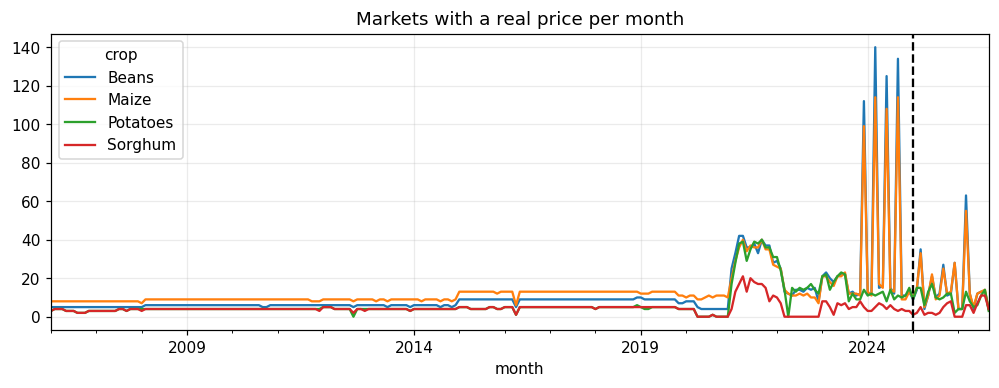

          series  ready
crop                   
Beans        220      5
Maize        208      2
Potatoes      56      3
Sorghum       34      0


In [17]:
# Coverage per month: how many real series report (train vs test)
cov=led.groupby(['month','crop']).market.nunique().unstack().fillna(0)
cov.index=cov.index.to_timestamp(); ax=cov.plot(figsize=(11,3.5),title='Markets with a real price per month'); ax.axvline(pd.Timestamp('2025-01-01'),c='k',ls='--'); plt.show()
print(inv.groupby('crop').agg(series=('months','size'),ready=('model_ready','sum')))

**What it shows:** How many markets report a real price each month, by crop. The dashed line is the start of the test period (2025).

**Insight:** Coverage is thin and steady (under 15 markets) until 2021, then jumps when WFP adds more markets, especially refugee camp markets. The tall spikes in 2024 and 2025 are months when many markets report at once, not a steady increase. Sorghum has the fewest markets throughout.

**What it means for SokoRadar:** The test period has real data, but it is uneven month to month. Scores should be reported per crop, and sorghum results will rest on very few markets.

In [18]:
# The 2023-24 finding, stated precisely: national reference prices vs WFP county markets
y2324 = slice(pd.Period('2023-01','M'), pd.Period('2024-12','M'))
core_real = int(REAL.loc[y2324, CORE].values.sum()); core_tot = int(REAL.loc[y2324, CORE].size)
others = REAL.loc[y2324].sum(); others = others[others>0]
print(f'NATIONAL reference prices, core series, 2023-24: {core_real} real months of {core_tot} -> entirely estimated' if core_real==0 else f'NATIONAL core series, 2023-24: {core_real} real months of {core_tot}')
print('Other national series with any real month in 2023-24:', others.to_dict() or 'none')
l2324 = led[(led.month>=pd.Period('2023-01','M')) & (led.month<=pd.Period('2024-12','M'))]
print(f'WFP COUNTY markets, 2023-24: {len(l2324)} real market-crop-months | {l2324.market.nunique()} markets | {l2324.admin2.nunique()} counties')
print(l2324.groupby(['flag']).size().to_dict(), '(flag counts) |', l2324.groupby('crop').size().to_dict())
print('=> the national reference prices for 2023-24 are entirely estimated; WFP county markets still have real prices in those years.')

NATIONAL reference prices, core series, 2023-24: 0 real months of 96 -> entirely estimated
Other national series with any real month in 2023-24: none
WFP COUNTY markets, 2023-24: 2010 real market-crop-months | 187 markets | 24 counties
{'actual': 1267, 'aggregate': 743} (flag counts) | {'Beans': 823, 'Maize': 737, 'Potatoes': 330, 'Sorghum': 120}
=> the national reference prices for 2023-24 are entirely estimated; WFP county markets still have real prices in those years.


## 10. Test period readiness (2025-01 to 2026-09)

In [19]:
T=led[led.month>pd.Period(TRAIN[1])]
print('Test months present:',T.month.nunique(),'| markets reporting:',T.market.nunique())
print(T.groupby('crop').agg(rows=('kes_kg','size'),markets=('market','nunique')))
print('Score only series that are alive in the test period. If no series is both long and alive, pool markets by crop (county-level model) instead of per-series models.')

Test months present: 21 | markets reporting: 93
          rows  markets
crop                   
Beans      323       92
Maize      317       86
Potatoes   198       17
Sorghum     83       12
Score only series that are alive in the test period. If no series is both long and alive, pool markets by crop (county-level model) instead of per-series models.


## 11. Chart pack
Same style as the `Charts` sheet in the workbook, rebuilt on the evidence tiers above for train 2006-2024. Every figure is also saved to `figures/`. Chart 6 is the bar-chart version; the real-data maps are Charts 17-18.

**Labelling in the charts:** grey shading = estimated months (darker = back-cast/filled, lighter = thin MoA). Charts built from county ledger data use WFP `actual` + `aggregate` prices; both are real. Charts 7 and 16 show [EST] and [REAL] next to each other.

In [20]:
from matplotlib.colors import ListedColormap
import matplotlib.dates as mdates
def save(name): plt.savefig(FIG/name, dpi=150, bbox_inches='tight')
BLUE, ORANGE, GREY = '#2a78d8', '#e8683a', '#bdbdb8'
idx_ts = P.loc[tr].index.to_timestamp()
def shade(ax, c):
    for p in P.loc[tr].index:
        t = p.to_timestamp()
        if not REAL.loc[p, c]:
            ax.axvspan(t, t + pd.offsets.MonthEnd(1), color=GREY, alpha=.35 if not THIN.loc[p,c] else .15, lw=0)

### Chart 1. National prices 2006-2024 (index Jan 2019 = 100). Grey = estimated, light grey = thin (1-9 trading days)

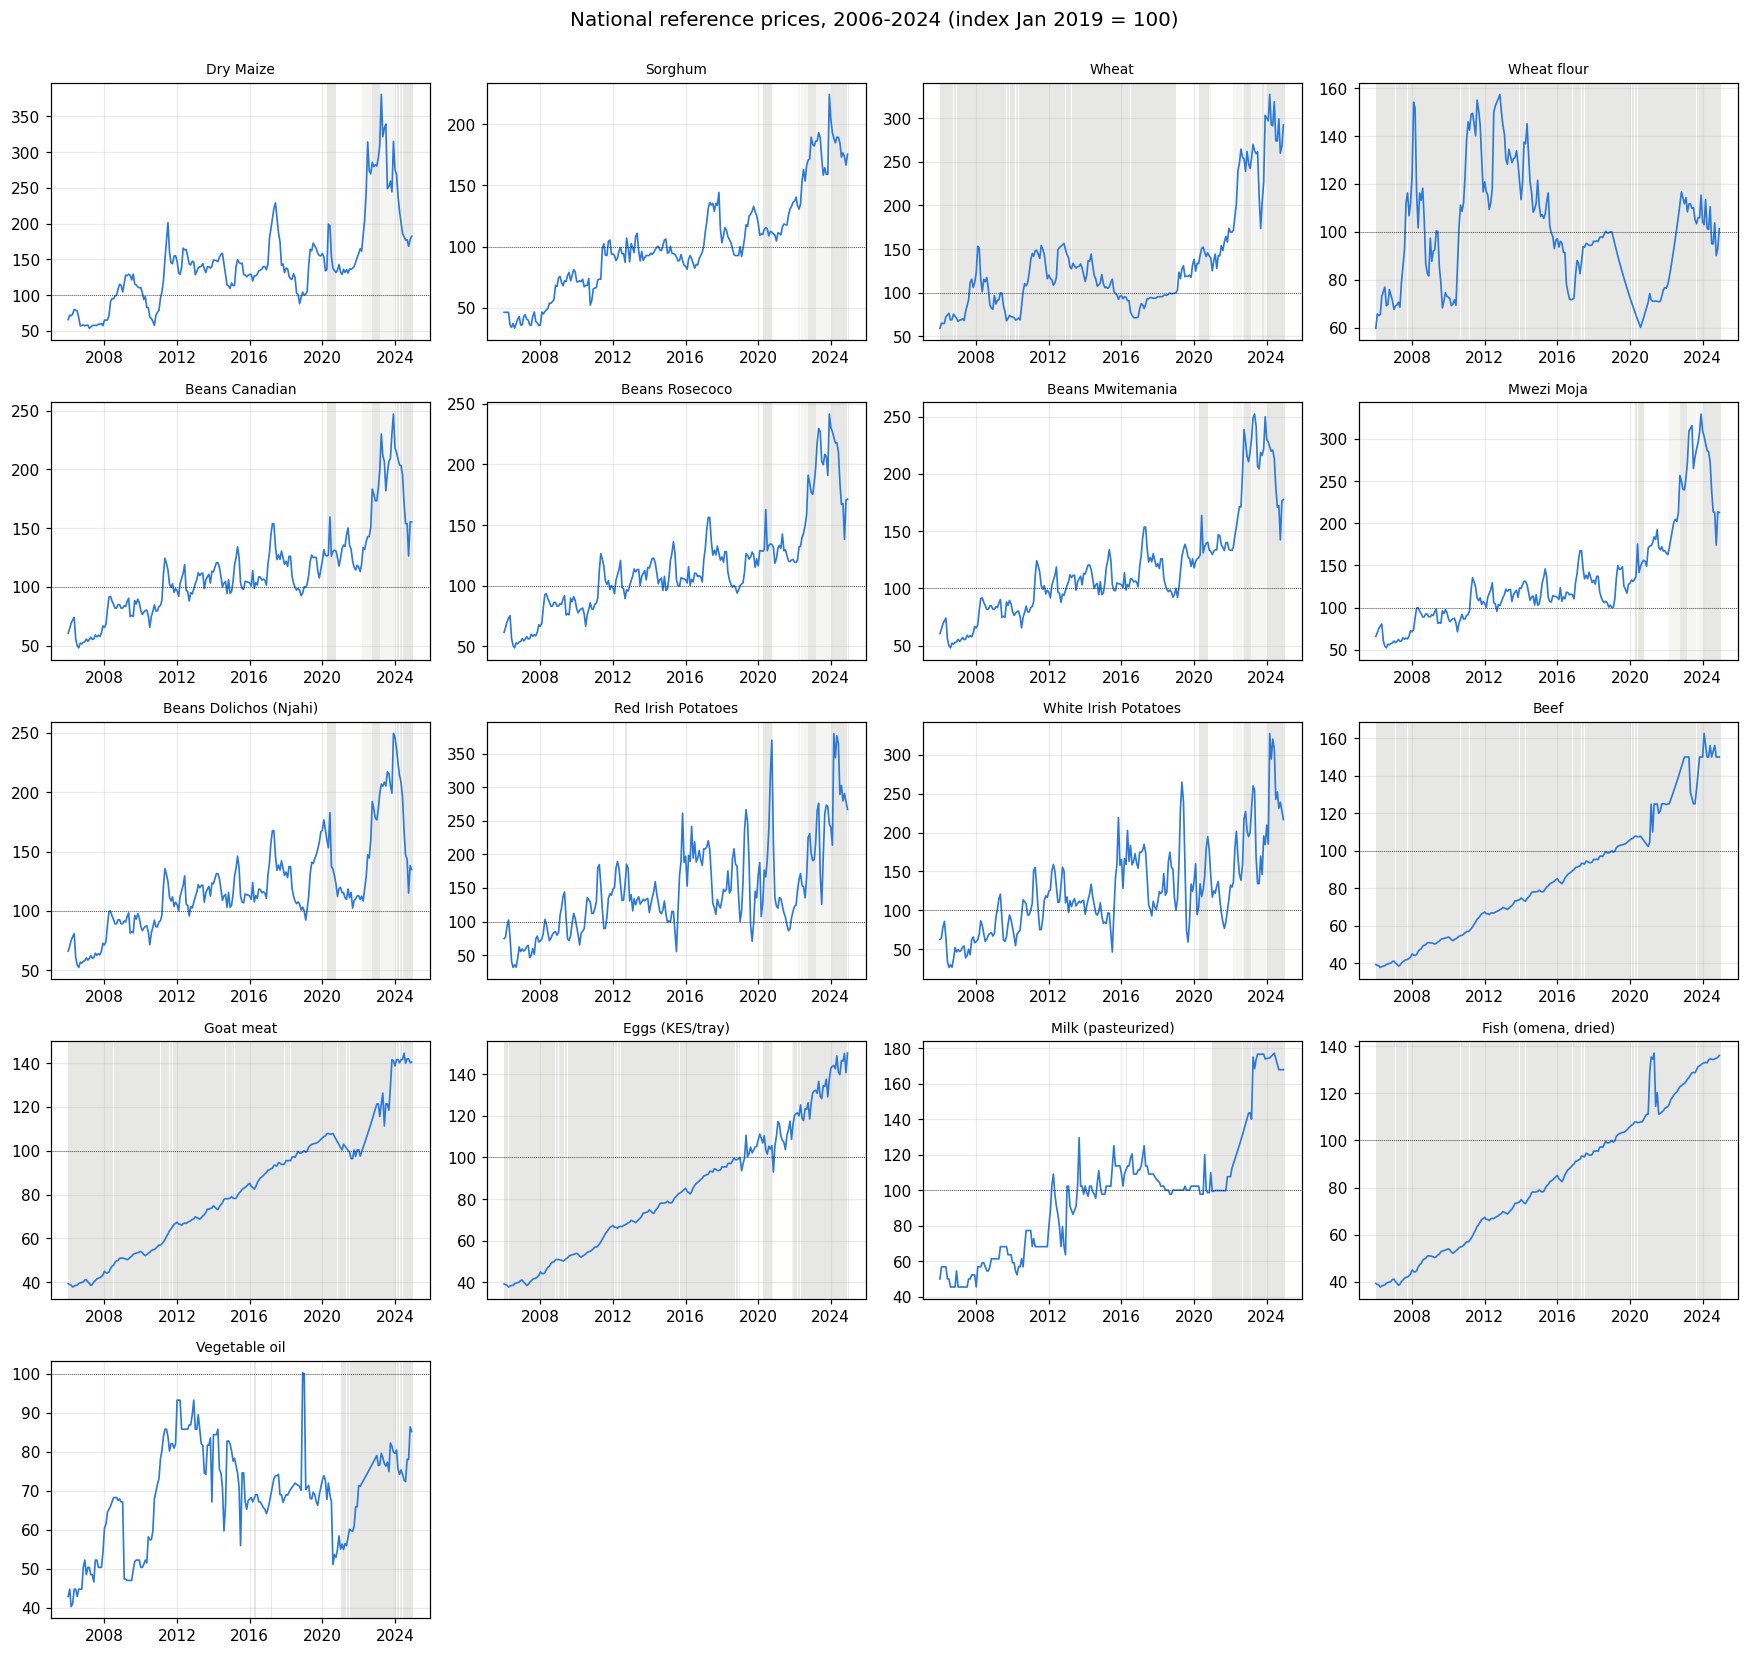

In [21]:
fig, axs = plt.subplots(5, 4, figsize=(16, 15)); axs = axs.ravel()
for ax, c in zip(axs, names):
    s = P.loc[tr, c]; ax.plot(idx_ts, 100*s/P.loc[pd.Period('2019-01','M'), c], color=BLUE, lw=1.1); ax.axhline(100, c='k', lw=.5, ls=':')
    shade(ax, c); ax.set_title(c, fontsize=9); ax.xaxis.set_major_locator(mdates.YearLocator(4)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
for ax in axs[len(names):]: ax.axis('off')
fig.suptitle('National reference prices, 2006-2024 (index Jan 2019 = 100)', y=1.0, fontsize=13); plt.tight_layout(); save('c01_national_index.png'); plt.show()

**What it shows:** Every national price series from 2006 to 2024, scaled so January 2019 = 100. Grey shading marks estimated months.

**Insight:** Maize, sorghum, beans and potatoes move with real ups and downs. Beef, goat meat, fish and eggs are almost straight rising lines inside grey shading, which is what a back cast trend looks like, not a market. The five bean types look nearly identical.

**What it means for SokoRadar:** Smooth straight lines are a warning sign of filled data. Those series are kept for display only, and the five bean types are treated as one series.

### Chart 2. Data coverage by month and commodity (MoA observed / WFP real / thin / estimated)

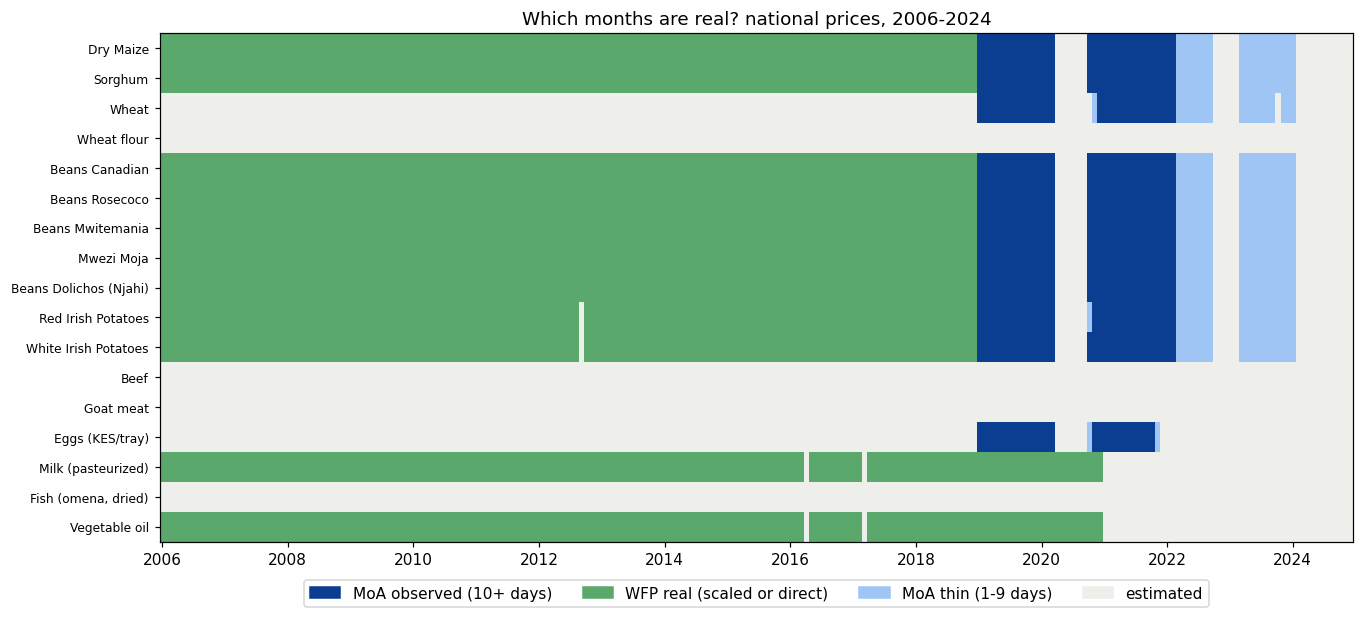

In [22]:
code_ = REAL_MOA.loc[tr].astype(int)*3 + (REAL.loc[tr] & ~REAL_MOA.loc[tr]).astype(int)*2 + THIN.loc[tr].astype(int)
fig, ax = plt.subplots(figsize=(14, 6))
ax.imshow(code_.T.values, aspect='auto', cmap=ListedColormap(['#eeeeea', '#9ec5f4', '#5aa86b', '#0b3d91']), interpolation='nearest', vmin=0, vmax=3)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8); ax.grid(False)
ix = code_.index; tk = [i for i, p in enumerate(ix) if p.month == 1 and p.year % 2 == 0]; ax.set_xticks(tk); ax.set_xticklabels([ix[i].year for i in tk])
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#0b3d91', label='MoA observed (10+ days)'), Patch(color='#5aa86b', label='WFP real (scaled or direct)'), Patch(color='#9ec5f4', label='MoA thin (1-9 days)'), Patch(color='#eeeeea', label='estimated')], loc='upper center', bbox_to_anchor=(.5, -.06), ncol=4)
ax.set_title('Which months are real? national prices, 2006-2024'); save('c02_coverage.png'); plt.show()

**What it shows:** For each commodity and month, where the price comes from: Ministry observed (dark blue), WFP real (green), Ministry thin with 1 to 9 trading days (light blue), or estimated (grey).

**Insight:** Before 2019 the core crops rely on WFP prices. Ministry data covers 2019 to early 2022 with a gap in mid 2020. In 2022 and 2023 there are only thin months, and 2024 is fully estimated.

**What it means for SokoRadar:** The training years 2023 and 2024 rest on estimates at national level. This is why the team shows every result as [EST] and [REAL].

### Chart 3. Counties with real WFP prices each year (retail vs wholesale), 2006 to 2026

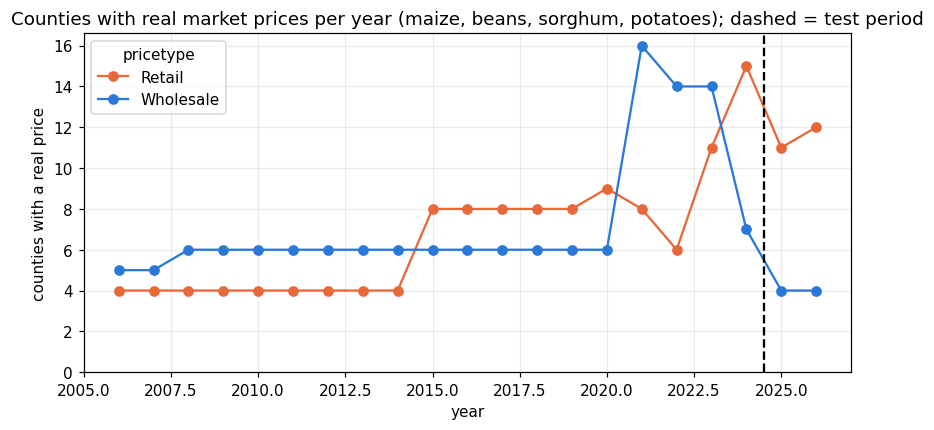

In [23]:
yy = led.assign(year=led.month.dt.year).groupby(['year', 'pricetype']).admin2.nunique().unstack()
ax = yy.plot(marker='o', figsize=(9, 4), color=[ORANGE, BLUE][:yy.shape[1]]); ax.axvline(2024.5, c='k', ls='--'); ax.set_ylabel('counties with a real price'); ax.set_ylim(0)
ax.set_title('Counties with real market prices per year (maize, beans, sorghum, potatoes); dashed = test period'); save('c03_counties_real.png'); plt.show()

**What it shows:** How many counties have at least one real market price each year, split into retail and wholesale. The dashed line is the start of the test period.

**Insight:** From 2006 to 2020 only 4 to 9 counties have real prices. Wholesale coverage peaks at 16 counties in 2021 and then falls to 4 in the test years. Retail rises to 15 counties in 2024 and stays at 11 to 12 in the test years.

**What it means for SokoRadar:** The test period depends mostly on retail prices. A model trained mainly on wholesale prices should be checked on retail before we trust its test score.

### Chart 4. Outliers removed in the pipeline (Cleaning_Log)

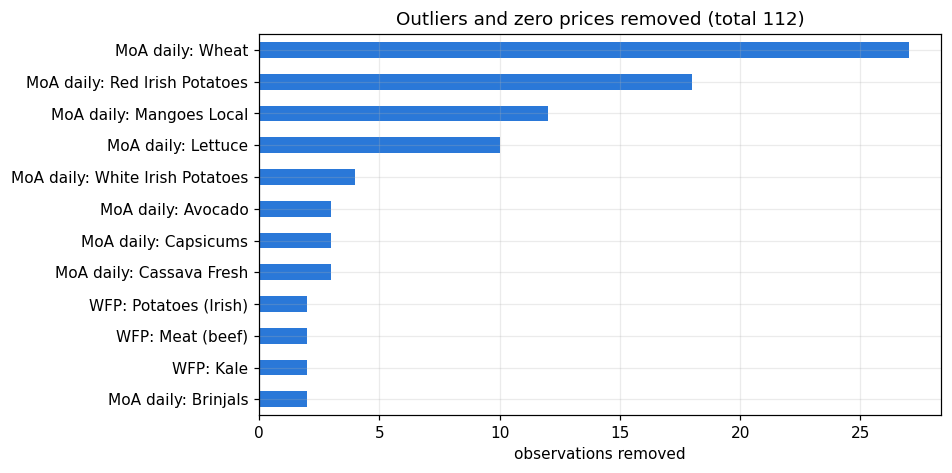

Stale values are not caught by the 3x rule: check flat runs below.
{'Milk (pasteurized)': 42}


In [24]:
try:
    cl = pd.read_excel(XLSX, 'Cleaning_Log', header=3)
    cl = cl[cl['action'].notna()]
    cnt = (cl['dataset'].astype(str) + ': ' + cl['commodity'].astype(str)).value_counts().head(12)[::-1]
    fig, ax = plt.subplots(figsize=(8, 4.5)); cnt.plot.barh(color=BLUE, ax=ax); ax.set_xlabel('observations removed')
    ax.set_title(f'Outliers and zero prices removed (total {len(cl)})'); save('c04_outliers.png'); plt.show()
    print('Stale values are not caught by the 3x rule: check flat runs below.')
except Exception as e: print('Cleaning_Log not readable:', e)
# stale-run check on national series (identical value 6+ months in a row)
st = {c: int((P[c].groupby((P[c] != P[c].shift()).cumsum()).transform('size') >= 6).sum()) for c in names}
print({k: v for k, v in st.items() if v})

**What it shows:** The number of price records removed during cleaning (outliers and zero prices), by source and commodity.

**Insight:** Only 112 records were removed in total. Most came from Ministry daily wheat (27) and red Irish potatoes (18). WFP records needed very few removals.

**What it means for SokoRadar:** Cleaning was light, so it does not reshape the data. Wheat and potatoes are the noisiest raw sources, which matches the high volatility of potatoes later in the notebook.

### Chart 5. Retail markup over wholesale (real county-months where both exist)

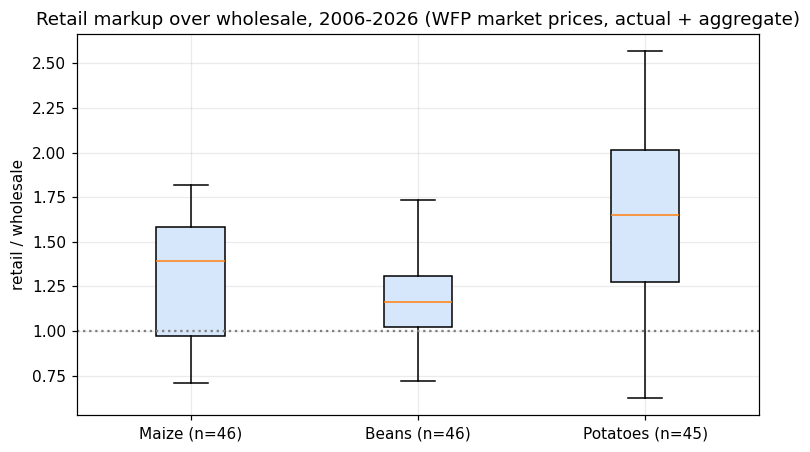

In [25]:
mk = led.pivot_table(index=['admin2', 'crop', 'month'], columns='pricetype', values='kes_kg', aggfunc='median').dropna()
mk['ratio'] = mk['Retail'] / mk['Wholesale']; mk = mk[(mk.ratio > .2) & (mk.ratio < 6)]
crops = [c for c in ['Maize', 'Beans', 'Sorghum', 'Potatoes'] if c in mk.index.get_level_values('crop')]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([mk.xs(c, level='crop').ratio.values for c in crops], showfliers=False, patch_artist=True, boxprops=dict(facecolor='#d6e6fb'))
ax.set_xticks(range(1, len(crops)+1)); ax.set_xticklabels([c + ' (n=' + str(len(mk.xs(c, level='crop'))) + ')' for c in crops])
ax.axhline(1, c='grey', ls=':'); ax.set_ylabel('retail / wholesale'); ax.set_title('Retail markup over wholesale, 2006-2026 (WFP market prices, actual + aggregate)'); save('c05_markup.png'); plt.show()

**What it shows:** Retail price divided by wholesale price in the same county and month, for maize, beans and potatoes.

**Insight:** Retail maize is typically about 40% above wholesale, beans about 15%, and potatoes about 65%, with a very wide spread for potatoes. Some ratios fall below 1, which should not normally happen and points to different markets or units being matched.

**What it means for SokoRadar:** Retail and wholesale prices must not be mixed in one series. An alert threshold set on wholesale prices would fire too often on retail prices.

### Chart 6. Where maize is dearer or cheaper than the cross-market median (real county prices; replaces the map)

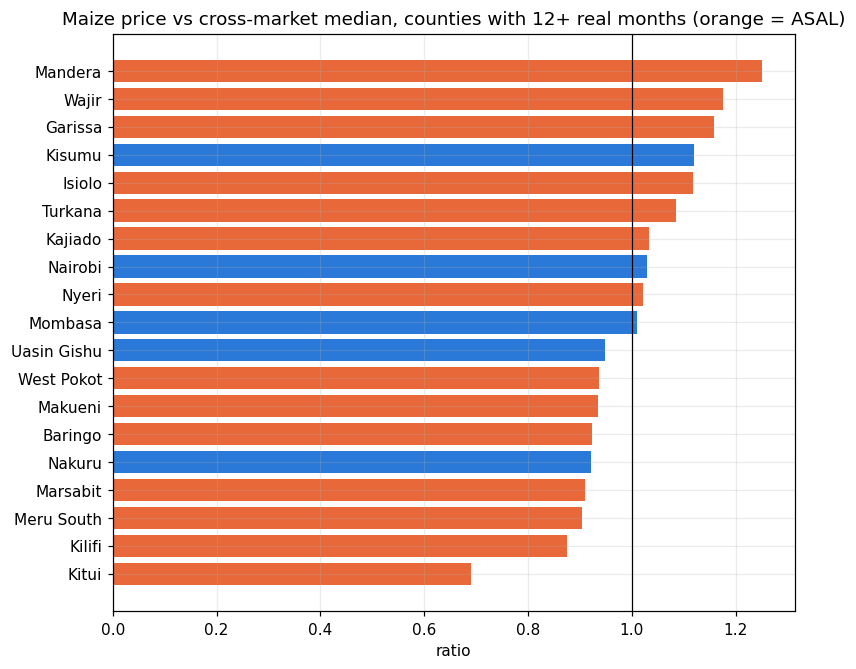

In [26]:
cty = pd.read_csv(DATA/'counties.csv'); cty['key'] = cty.county.str.lower().str.replace(r'[^a-z]', '', regex=True)
mz = led[led.crop == 'Maize'].copy()
mz['rel'] = mz.kes_kg / mz.groupby(['month', 'pricetype']).kes_kg.transform('median')
g = mz.groupby('admin2').agg(rel=('rel', 'mean'), n=('month', 'nunique')).query('n >= 12').sort_values('rel')
g['key'] = g.index.str.lower().str.replace(r'[^a-z]', '', regex=True); g = g.merge(cty[['key', 'asal']], on='key', how='left').set_index(g.index)
fig, ax = plt.subplots(figsize=(8, 0.28*len(g) + 1.5))
ax.barh(g.index, g.rel, color=[ORANGE if str(a) != 'Non-ASAL' else BLUE for a in g.asal]); ax.axvline(1, c='k', lw=.8)
ax.set_title('Maize price vs cross-market median, counties with 12+ real months (orange = ASAL)'); ax.set_xlabel('ratio'); save('c06_county_ratio.png'); plt.show()

**What it shows:** Each county's average maize price compared with the median across markets, for counties with at least 12 real months. Orange bars are arid and semi arid (ASAL) counties.

**Insight:** Mandera, Wajir and Garissa are the dearest, about 15 to 25% above the median. Kitui is the cheapest, about 30% below. Being ASAL does not always mean dear: Marsabit, Makueni and Kitui sit below the median.

**What it means for SokoRadar:** Distance from producing areas matters more than dryness alone. The northeast is where high prices hurt most, so county level alerts there deserve priority.

### Chart 7. Which prices move together? All months vs real consecutive months only

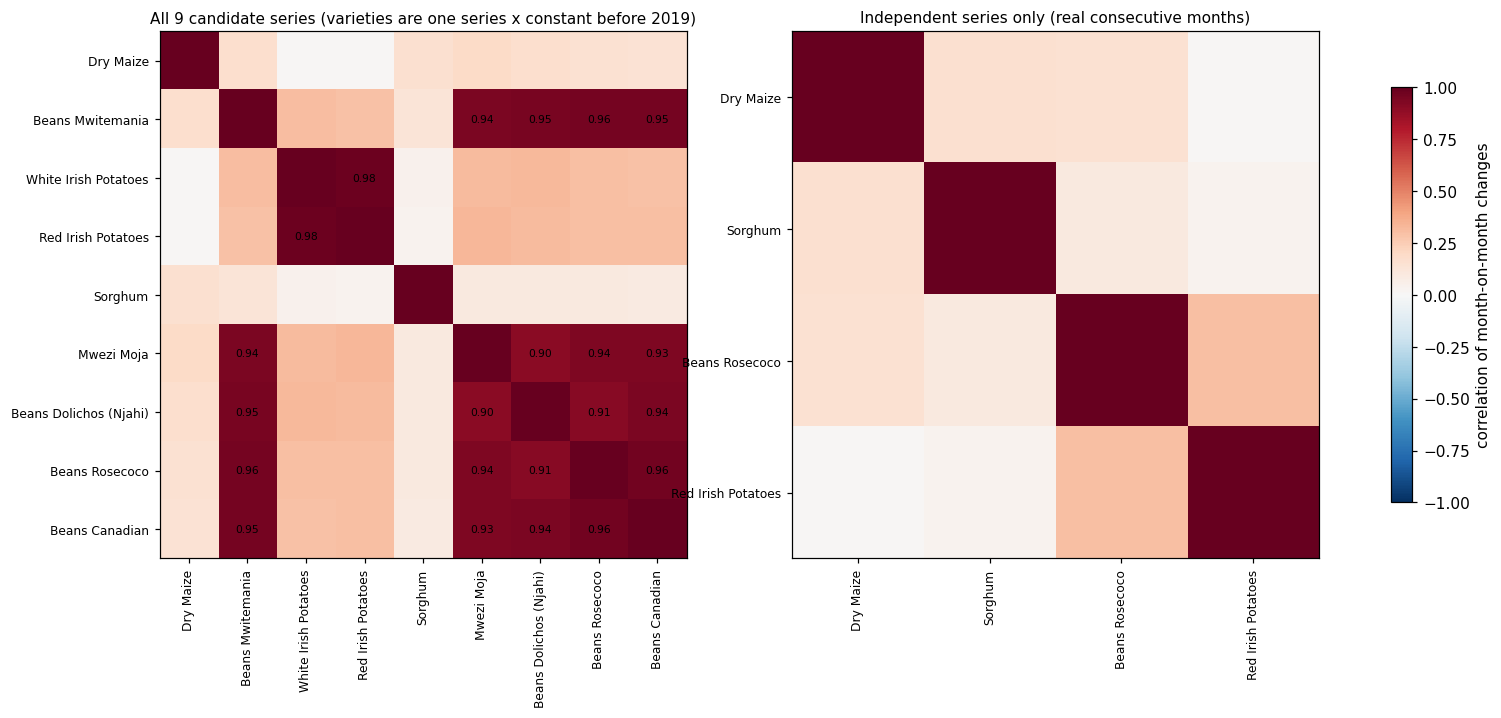

In [27]:
pm = REAL.loc[tr] & REAL.loc[tr].shift(1, fill_value=False)
Rc = np.log(P.loc[tr, CAND]).diff().where(pm[CAND])
fig, axs = plt.subplots(1, 2, figsize=(17, 7))
for ax, d, t in zip(axs, [Rc.corr(min_periods=15), Rr.corr(min_periods=15)], ['All %d candidate series (varieties are one series x constant before 2019)' % len(CAND), 'Independent series only (real consecutive months)']):
    im = ax.imshow(d.values, cmap='RdBu_r', vmin=-1, vmax=1); ax.set_xticks(range(len(d))); ax.set_yticks(range(len(d)))
    ax.set_xticklabels(d.columns, rotation=90, fontsize=8); ax.set_yticklabels(d.index, fontsize=8); ax.grid(False); ax.set_title(t, fontsize=10)
    for i in range(len(d)):
        for j in range(len(d)):
            if i != j and abs(d.values[i, j]) >= .4: ax.text(j, i, f'{d.values[i,j]:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im, ax=axs, shrink=.7, label='correlation of month-on-month changes'); save('c07_correlation.png'); plt.show()

**What it shows:** Left: how closely monthly price changes move together across all 9 candidate series. Right: the same for the 4 independent series, using real consecutive months only.

**Insight:** On the left, the bean types correlate at 0.90 to 0.96 and the two potato types at 0.98, so they are copies of one series. On the right, maize, sorghum, beans and potatoes barely move together month to month; only beans and potatoes show a weak link.

**What it means for SokoRadar:** Each crop needs its own model. Knowing this month's maize change tells us little about this month's sorghum change.

### Chart 8. National maize with drought months shaded (3-month rain below 75% of normal)

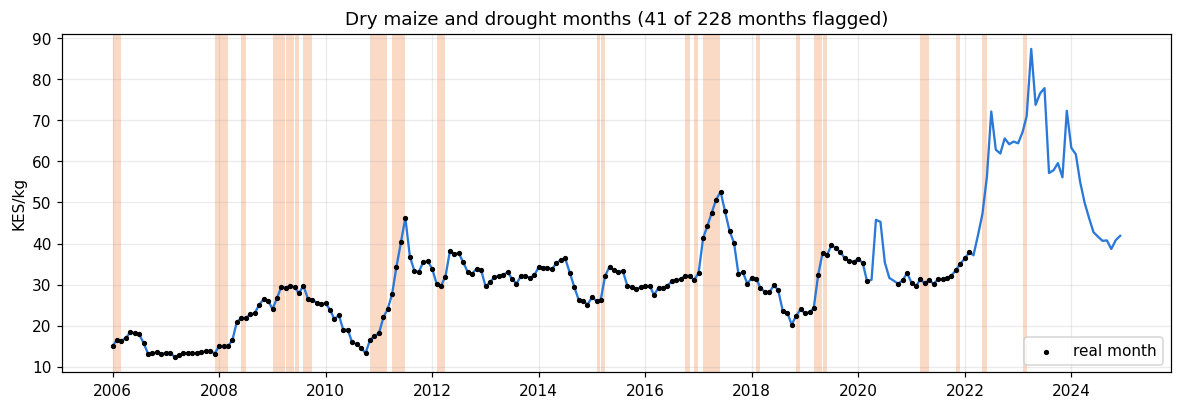

In [28]:
dr = (D['Rainfall last 3 months, % of normal'] < 75).loc[tr]; s = P.loc[tr, 'Dry Maize']
fig, ax = plt.subplots(figsize=(13, 4)); ax.plot(idx_ts, s.values, color=BLUE)
for p, v in dr.items():
    if v: ax.axvspan(p.to_timestamp(), p.to_timestamp() + pd.offsets.MonthEnd(1), color='#f9c9ad', alpha=.7, lw=0)
r_ = REAL.loc[tr, 'Dry Maize']; ax.scatter(idx_ts[r_.values], s[r_].values, s=6, c='k', zorder=3, label='real month')
ax.set_ylabel('KES/kg'); ax.legend(); ax.set_title(f'Dry maize and drought months ({int(dr.sum())} of {len(dr)} months flagged)'); save('c08_maize_drought.png'); plt.show()

**What it shows:** National maize price in KES per kg, with drought months shaded (3 month rain below 75% of normal). Black dots are real months.

**Insight:** The big real price peaks (2008 to 2009, 2011, 2017 and 2019) all come during or just after shaded drought periods. The highest point, about KES 87 in 2023, has no black dots, so it is estimated.

**What it means for SokoRadar:** This is the clearest visual support for SokoRadar's alert idea: dry spells come before price jumps. It matches the test above, where a dry spell adds about 15 percentage points to the 3 month maize rise on real months too.

### Chart 9. Seasonal heatmap: maize deviation from its yearly mean (real months only)

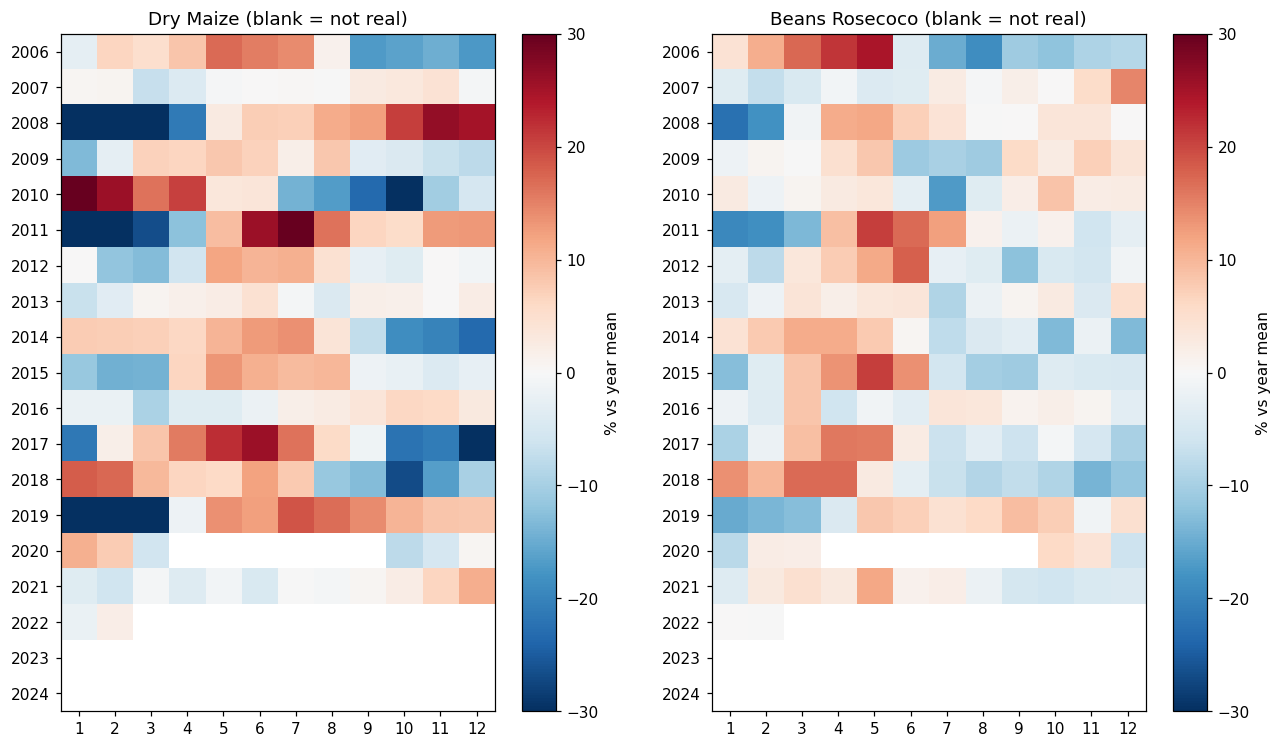

In [29]:
def season_heat(c):
    s = np.log(P.loc[tr, c]).where(REAL.loc[tr, c]); dev = s - s.groupby(s.index.year).transform('mean')
    return dev.groupby([dev.index.year, dev.index.month]).mean().unstack()
fig, axs = plt.subplots(1, 2, figsize=(14, 8))
for ax, c in zip(axs, ['Dry Maize', 'Beans Rosecoco']):
    h = 100*season_heat(c); im = ax.imshow(h.values, cmap='RdBu_r', vmin=-30, vmax=30, aspect='auto')
    ax.set_xticks(range(h.shape[1])); ax.set_xticklabels(h.columns); ax.set_yticks(range(h.shape[0])); ax.set_yticklabels(h.index); ax.grid(False); ax.set_title(c + ' (blank = not real)')
    plt.colorbar(im, ax=ax, label='% vs year mean')
save('c09_seasonal_heat.png'); plt.show()

**What it shows:** Maize and beans prices for each month compared with that year's average, real months only. Red is dearer than usual, blue is cheaper. Blank cells are not real.

**Insight:** Maize often turns red in May to July and blue in October to January after harvest, but some years (2008, 2010, 2011) swing far more than others. Beans peak earlier, around March to May, and the pattern is weaker. 2022 to 2024 are blank.

**What it means for SokoRadar:** Season explains part of the price path, but the year matters as much. Rainfall and drought flags are needed on top of month of year.

### Chart 10. Rolling volatility of month-on-month changes (6 months)

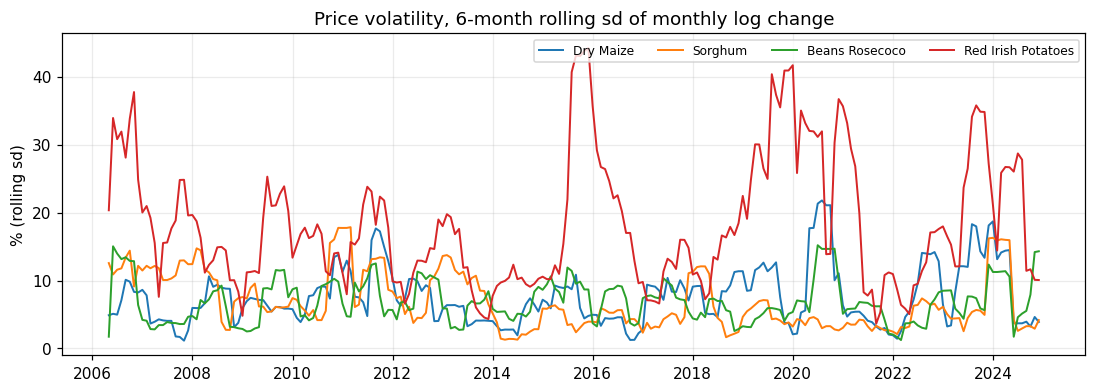

In [30]:
fig, ax = plt.subplots(figsize=(12, 3.8))
for c in ['Dry Maize', 'Sorghum', 'Beans Rosecoco', 'Red Irish Potatoes']:
    if c in CORE: ax.plot(idx_ts, 100*R[c].rolling(6, min_periods=4).std().values, label=c, lw=1.3)
ax.set_ylabel('% (rolling sd)'); ax.legend(ncol=4, fontsize=8); ax.set_title('Price volatility, 6-month rolling sd of monthly log change'); save('c10_volatility.png'); plt.show()

**What it shows:** How volatile monthly price changes are, measured over a rolling 6 month window.

**Insight:** Potatoes are by far the most volatile, often 20 to 40%. Maize jumps in volatility in 2011, 2020 to 2021 and 2023 to 2024. Sorghum and beans usually stay around 5 to 10%.

**What it means for SokoRadar:** One alert threshold cannot fit every crop. Potatoes need a wider band, or they will raise false alarms constantly.

### Chart 11. Maize against exchange rate, diesel and food inflation

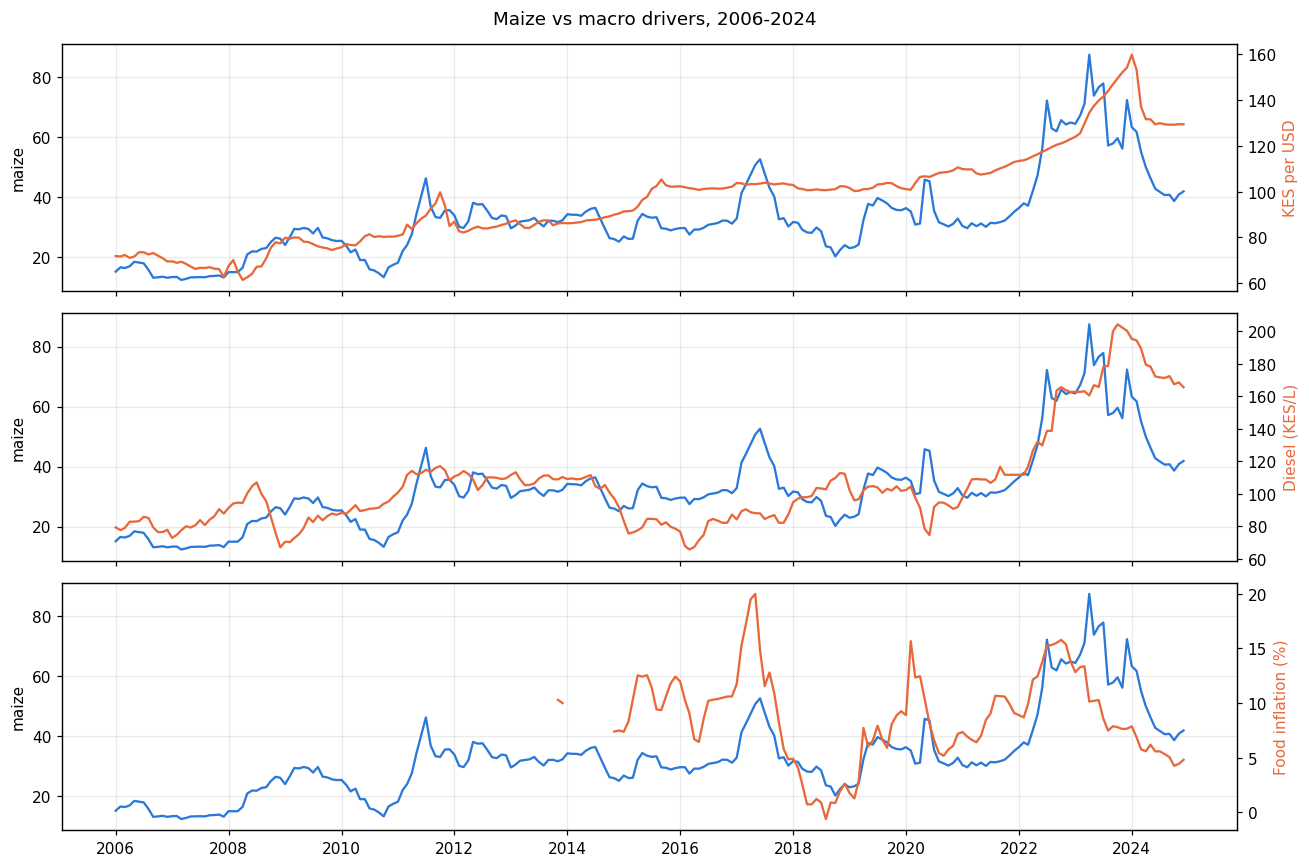

In [31]:
Dd = D.loc[tr]; fig, axs = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, col, lab in zip(axs, ['KES per USD', 'Diesel (KES/L)', 'Food inflation (%)'], ['KES per USD', 'Diesel (KES/L)', 'Food inflation (%)']):
    ax.plot(idx_ts, P.loc[tr, 'Dry Maize'].values, color=BLUE, label='Dry maize (KES/kg)'); ax2 = ax.twinx(); ax2.plot(idx_ts, Dd[col].values, color=ORANGE, label=lab); ax2.grid(False)
    ax.set_ylabel('maize'); ax2.set_ylabel(lab, color=ORANGE)
fig.suptitle('Maize vs macro drivers, 2006-2024'); plt.tight_layout(); save('c11_macro_drivers.png'); plt.show()

**What it shows:** National maize price against the KES/USD exchange rate, diesel price and food inflation.

**Insight:** Over the long run, maize rises with a weaker shilling. Maize and diesel both surge in 2022, and food inflation peaks in 2017 and 2022, the same years maize peaks. Month to month, however, the lines often move apart.

**What it means for SokoRadar:** These show shared trends and shared shocks, not cause. The next chart and the driver tests check whether any of them actually lead maize.

### Chart 12. Cross-correlation: maize monthly change vs driver changes (lags -6 to +6; positive lag = driver leads)

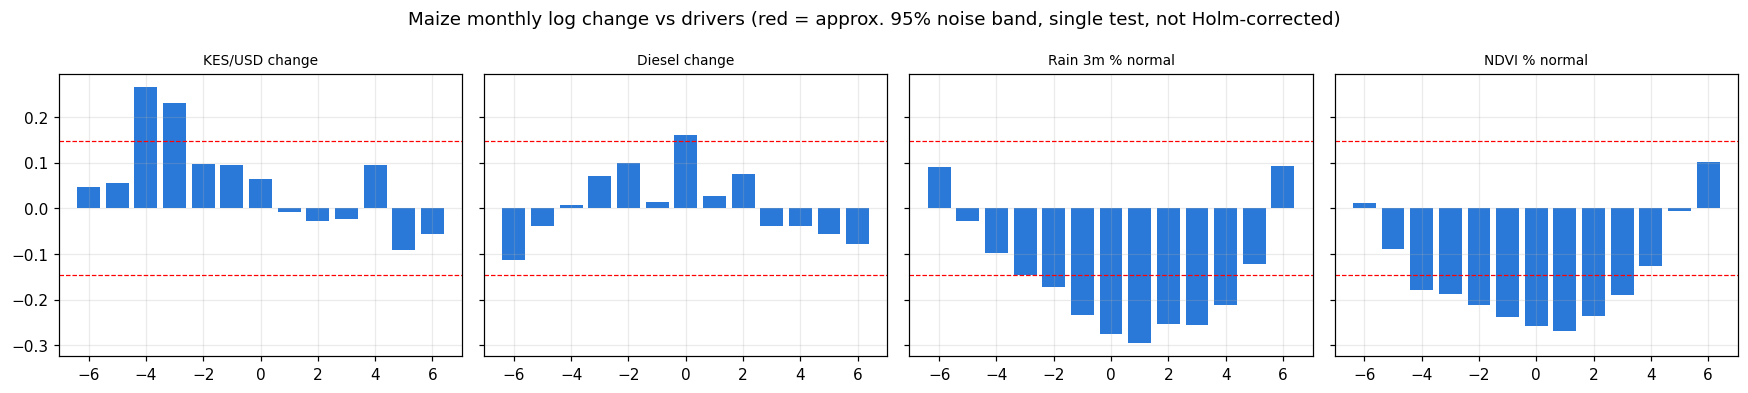

In [32]:
drv = {'KES/USD change': np.log(D['KES per USD']).diff().loc[tr], 'Diesel change': np.log(D['Diesel (KES/L)']).diff().loc[tr],
       'Rain 3m % normal': D['Rainfall last 3 months, % of normal'].loc[tr], 'NDVI % normal': D['Vegetation, % of normal'].loc[tr]}
fig, axs = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True); y = Rr['Dry Maize']
for ax, (k, x) in zip(axs, drv.items()):
    lags = range(-6, 7); cc = [y.corr(x.shift(l)) for l in lags]; ax.bar(lags, cc, color=BLUE); n = y.notna().sum(); ax.axhline(2/np.sqrt(n), c='r', ls='--', lw=.8); ax.axhline(-2/np.sqrt(n), c='r', ls='--', lw=.8); ax.set_title(k, fontsize=9)
fig.suptitle('Maize monthly log change vs drivers (red = approx. 95% noise band, single test, not Holm-corrected)'); plt.tight_layout(); save('c12_crosscorr.png'); plt.show()

**What it shows:** Correlation between monthly maize changes and changes in each driver, from 6 months before to 6 months after. Positive lag means the driver moves first. Bars outside the red lines are beyond normal noise for a single test.

**Insight:** Rainfall and vegetation (NDVI) show clear negative bars at lags 0 to 3: less rain is followed by higher maize prices over the next three months. Diesel stays mostly inside the noise band. The exchange rate bars that stand out are at negative lags, so maize moves first there, which is not useful for prediction.

**What it means for SokoRadar:** Rainfall and NDVI are the drivers worth using as early warning features. This agrees with the Holm corrected tests in section 7.

### Chart 13. County rainfall heatmap: 3-month rain as % of normal, 2006-2024

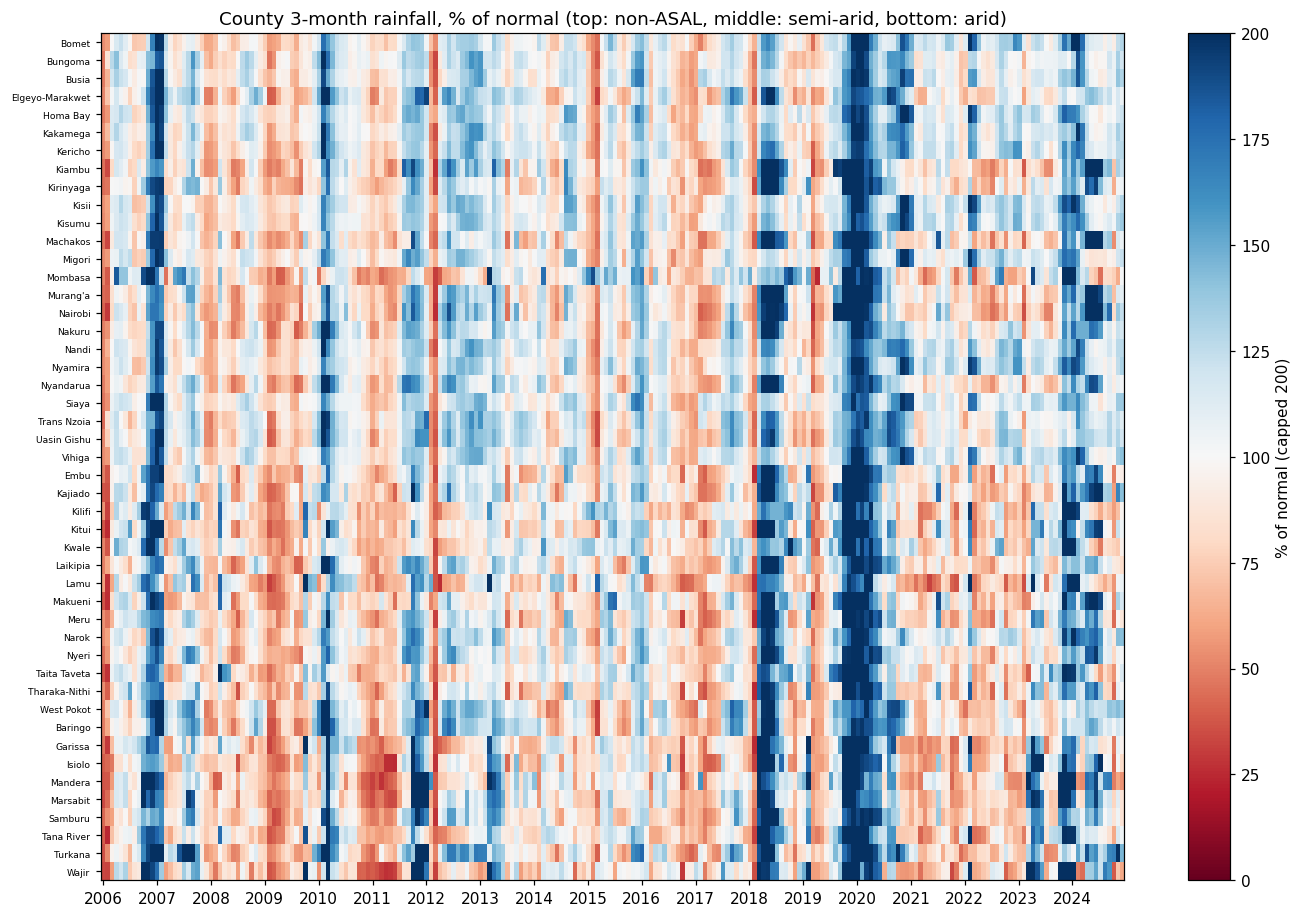

In [33]:
cl_ = pd.read_csv(DATA/'county_climate_chirps_ndvi.csv', parse_dates=['month']); cl_ = cl_[(cl_.month >= '2006-01-01') & (cl_.month <= '2024-12-31')]
cl_ = cl_.merge(cty[['pcode', 'county', 'asal']], left_on='county_pcode', right_on='pcode')
order = cty.assign(o=cty.asal.map({'Non-ASAL': 0, 'Semi-arid': 1}).fillna(2)).sort_values(['o', 'county']).county
H = cl_.pivot_table(index='county', columns='month', values='rain_3m_pct').reindex(order)
fig, ax = plt.subplots(figsize=(15, 10)); im = ax.imshow(H.clip(0, 200).values, aspect='auto', cmap='RdBu', vmin=0, vmax=200)
ax.set_yticks(range(len(H))); ax.set_yticklabels(H.index, fontsize=6); ax.grid(False)
tk = [i for i, m in enumerate(H.columns) if m.month == 1]; ax.set_xticks(tk); ax.set_xticklabels([H.columns[i].year for i in tk]); plt.colorbar(im, label='% of normal (capped 200)')
ax.set_title('County 3-month rainfall, % of normal (top: non-ASAL, middle: semi-arid, bottom: arid)'); save('c13_county_rain.png'); plt.show()

**What it shows:** Three month rainfall as a percentage of normal for every county and month. Blue is wetter than normal, red is drier. Counties are grouped as non ASAL (top), semi arid (middle) and arid (bottom).

**Insight:** Dry and wet periods run as vertical bands across almost all counties at once: dry in 2009, 2011, 2017 and 2021 to 2022, very wet in late 2006, 2018 and late 2019 to 2020. Arid counties at the bottom show deeper red.

**What it means for SokoRadar:** Droughts in Kenya are national events, so many counties hit alert level together. The alert system should expect clusters of alerts, not single counties.

### Chart 14. Drought exposure by ASAL class

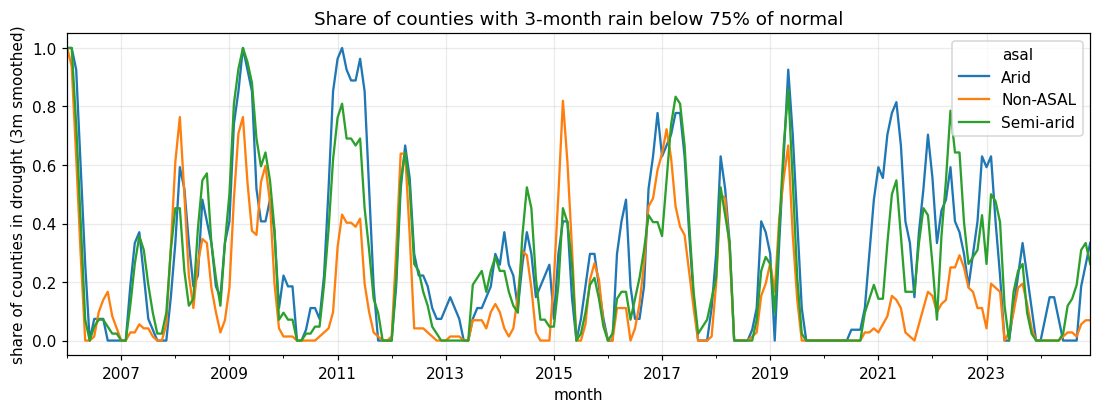

In [34]:
a = cl_.assign(drought=cl_.rain_3m_pct < 75).groupby(['month', 'asal']).drought.mean().unstack()
ax = a.rolling(3, min_periods=1).mean().plot(figsize=(12, 3.8)); ax.set_ylabel('share of counties in drought (3m smoothed)')
ax.set_title('Share of counties with 3-month rain below 75% of normal'); save('c14_drought_by_asal.png'); plt.show()

**What it shows:** The share of counties in drought each month, by ASAL class.

**Insight:** Arid counties enter drought more often and stay longer, for example 2011 and the long 2021 to 2023 drought. Non ASAL counties have short spikes, such as 2015 and 2019.

**What it means for SokoRadar:** The drought signal is strongest where people are most exposed. Alert thresholds may need to differ for arid and non ASAL counties.

### Chart 15. Distribution of monthly price changes (real consecutive months)

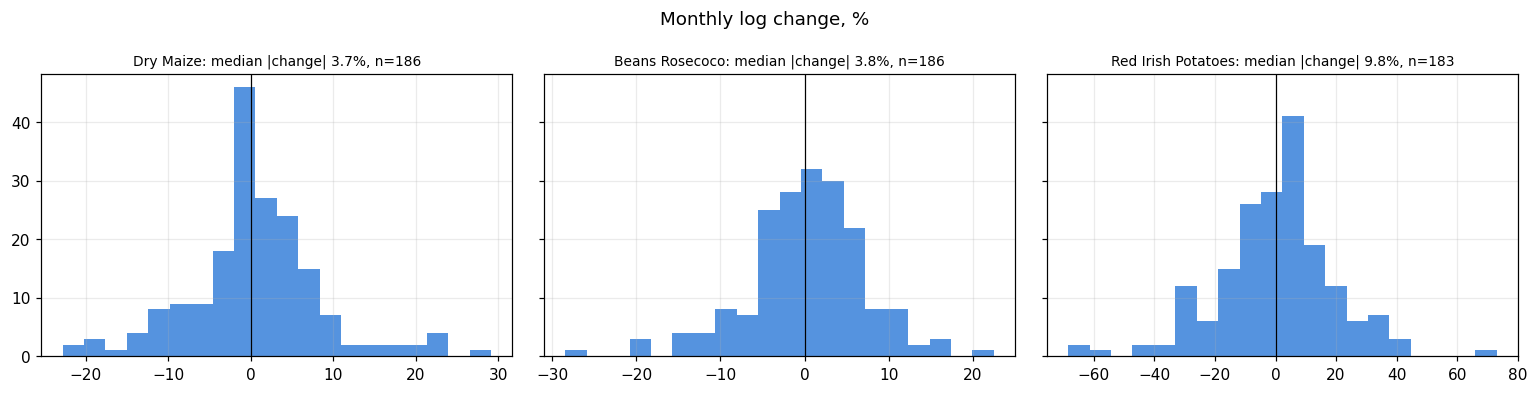

In [35]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, c in zip(axs, ['Dry Maize', 'Beans Rosecoco', 'Red Irish Potatoes']):
    r_ = R[c].where(pm[c]).dropna()*100; ax.hist(r_, bins=20, color=BLUE, alpha=.8); ax.axvline(0, c='k', lw=.8); ax.set_title(f'{c}: median |change| {r_.abs().median():.1f}%, n={len(r_)}', fontsize=9)
fig.suptitle('Monthly log change, %'); plt.tight_layout(); save('c15_change_hist.png'); plt.show()

**What it shows:** How big monthly price changes are, real consecutive months only.

**Insight:** Most months move only a little: the median change is about 3.7% for maize and 3.8% for beans, but 9.8% for potatoes. Maize has a longer right tail, with rises of 20 to 30% in some months.

**What it means for SokoRadar:** Big jumps are rare, and they are exactly what SokoRadar wants to catch. Because they are rare, recall on alert months matters more than overall accuracy.

### Chart 16. Baseline difficulty: naive vs seasonal-naive error by horizon, [EST] vs [REAL] side by side
The left panel includes estimated months (smoother, so errors look smaller); the right panel scores only real endpoints. Use the right panel as the bar a model has to beat.

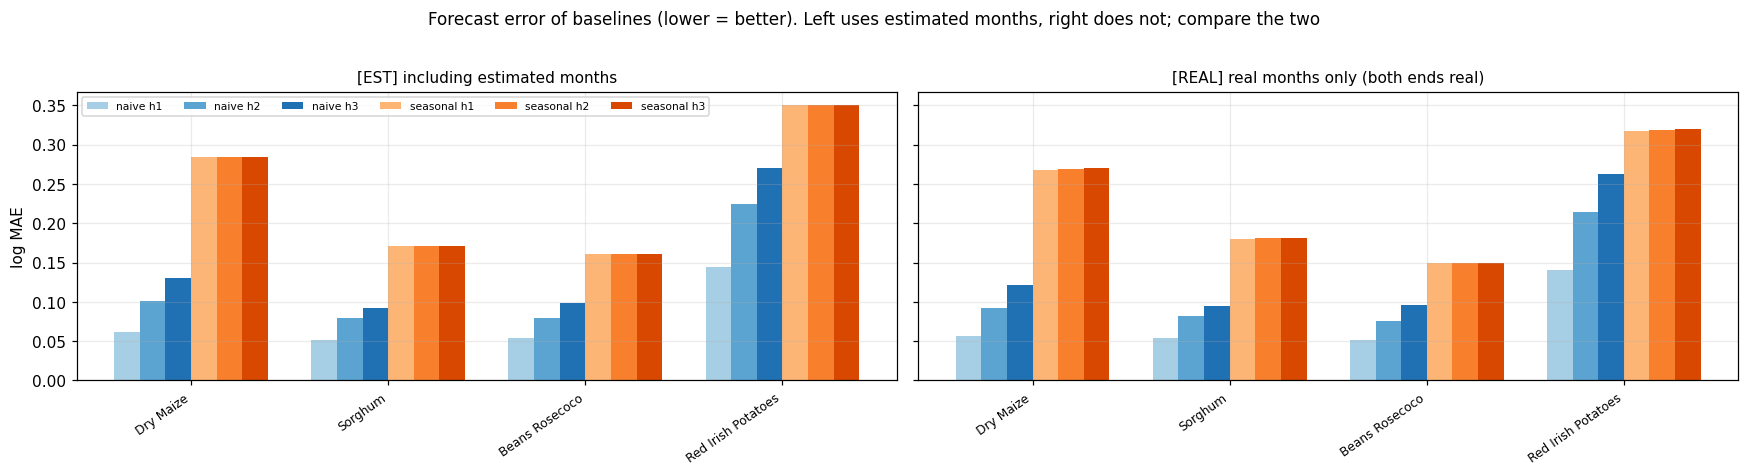

In [36]:
fig, axs = plt.subplots(1, 2, figsize=(16, 4.2), sharey=True); w = .13; xs = np.arange(len(B))
combos = [(t, h) for t in ('naive', 'seasonal') for h in (1, 2, 3)]
for ax, suffix, title in zip(axs, ['', ' (real ends)'], ['[EST] including estimated months', '[REAL] real months only (both ends real)']):
    for k, (t, h) in enumerate(combos):
        ax.bar(xs + (k-2.5)*w, B[f'{t} h{h}{suffix}'], w, label=f'{t} h{h}', color=(plt.cm.Blues if t == 'naive' else plt.cm.Oranges)(.35 + .2*(h-1)))
    ax.set_xticks(xs); ax.set_xticklabels(B.index, rotation=35, ha='right', fontsize=8); ax.set_title(title, fontsize=10)
axs[0].set_ylabel('log MAE'); axs[0].legend(ncol=6, fontsize=7)
fig.suptitle('Forecast error of baselines (lower = better). Left uses estimated months, right does not; compare the two', y=1.02, fontsize=11); plt.tight_layout(); save('c16_baselines.png'); plt.show()

**What it shows:** Forecast error of two simple baselines at 1, 2 and 3 months ahead. Naive means 'same as last month'; seasonal means 'same as the same month last year'. Left includes estimated months, right uses real months only.

**Insight:** Naive is always much better than seasonal. Error grows with horizon, and potatoes are the hardest. For maize 3 months ahead, the naive error is 0.130 including estimates and 0.121 on real months, so estimates make little difference here.

**What it means for SokoRadar:** Beating the seasonal baseline proves nothing. The real bar is naive: a model must cut maize 3 month error to about 0.117 to count as useful.

### Chart 17-18. Maps of Kenya
Needs `ken_counties.geojson` next to the notebook (extracted from your pipeline file). Map 1 colours **only counties with real maize prices**; the rest stay grey so no estimated value is shown as evidence. Map 2 uses CHIRPS rainfall, which is observed for every county.

In [37]:
import json
from matplotlib.patches import Polygon as MPoly
from matplotlib.collections import PatchCollection
from matplotlib import cm, colors as mcolors
assert (DATA/'ken_counties.geojson').exists(), 'ken_counties.geojson not found in sokoradar_raw_data/ (needed for the maps)'
GJ = json.load(open(DATA/'ken_counties.geojson'))
def rings(geom):
    polys = geom['coordinates'] if geom['type'] == 'MultiPolygon' else [geom['coordinates']]
    return [np.array(p[0]) for p in polys]
def draw_map(ax, values, cmap, norm, outline=None, label=''):
    pats, cols, edges = [], [], []
    for f in GJ['features']:
        pc = f['properties']['pcode']; v = values.get(pc, np.nan)
        for r in rings(f['geometry']):
            pats.append(MPoly(r, closed=True)); cols.append(cmap(norm(v)) if pd.notna(v) else '#e6e6e2')
            edges.append('black' if (outline is not None and pc in outline) else 'white')
    pc_ = PatchCollection(pats, facecolor=cols, edgecolor=edges, linewidths=[1.4 if e == 'black' else .4 for e in edges])
    ax.add_collection(pc_); ax.autoscale_view(); ax.set_aspect('equal'); ax.axis('off')
    sm = cm.ScalarMappable(norm=norm, cmap=cmap); plt.colorbar(sm, ax=ax, shrink=.6, label=label)

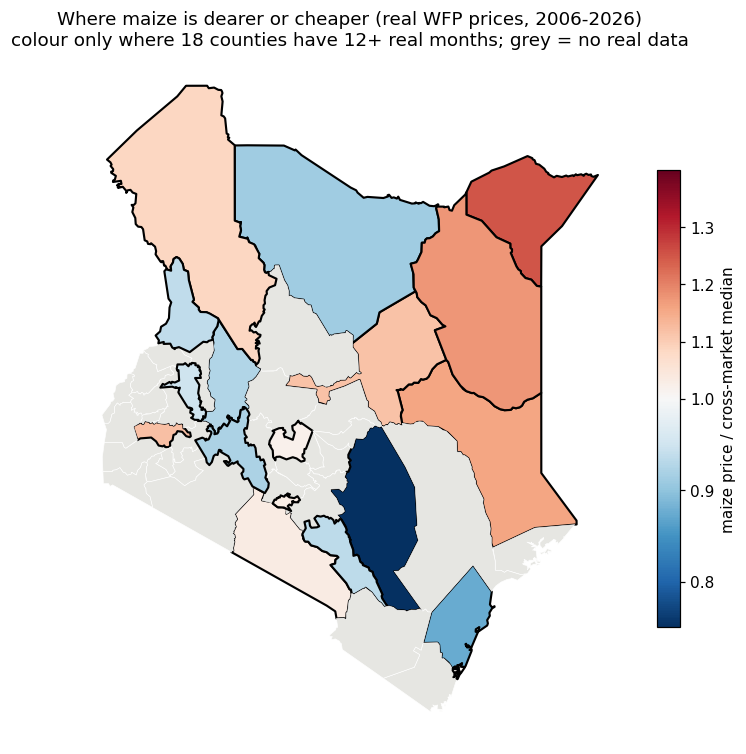

In [38]:
# Map 1: maize price vs cross-market median, real data only
key2pc = dict(zip(cty.key, cty.pcode))
g1 = g.copy(); g1['pcode'] = g1.key.map(key2pc); vals1 = g1.dropna(subset=['pcode']).set_index('pcode').rel.to_dict()
fig, ax = plt.subplots(figsize=(8, 9))
draw_map(ax, vals1, plt.cm.RdBu_r, mcolors.TwoSlopeNorm(1.0, .75, 1.4), outline=set(vals1), label='maize price / cross-market median')
ax.set_title(f'Where maize is dearer or cheaper (real WFP prices, 2006-2026)\ncolour only where {len(vals1)} counties have 12+ real months; grey = no real data')
save('c17_map_maize_ratio.png'); plt.show()

**What it shows:** Each county's maize price compared with the cross market median, coloured only where a county has 12 or more real months. Grey means no real data.

**Insight:** The northeast (Mandera, Wajir, Garissa) is dearest. Kitui is the cheapest, and the western and Rift Valley counties sit near or below the median. Large parts of the country are grey.

**What it means for SokoRadar:** Only 18 counties have enough real maize data. A national map showing every county would mostly be showing estimates, so the map should say so.

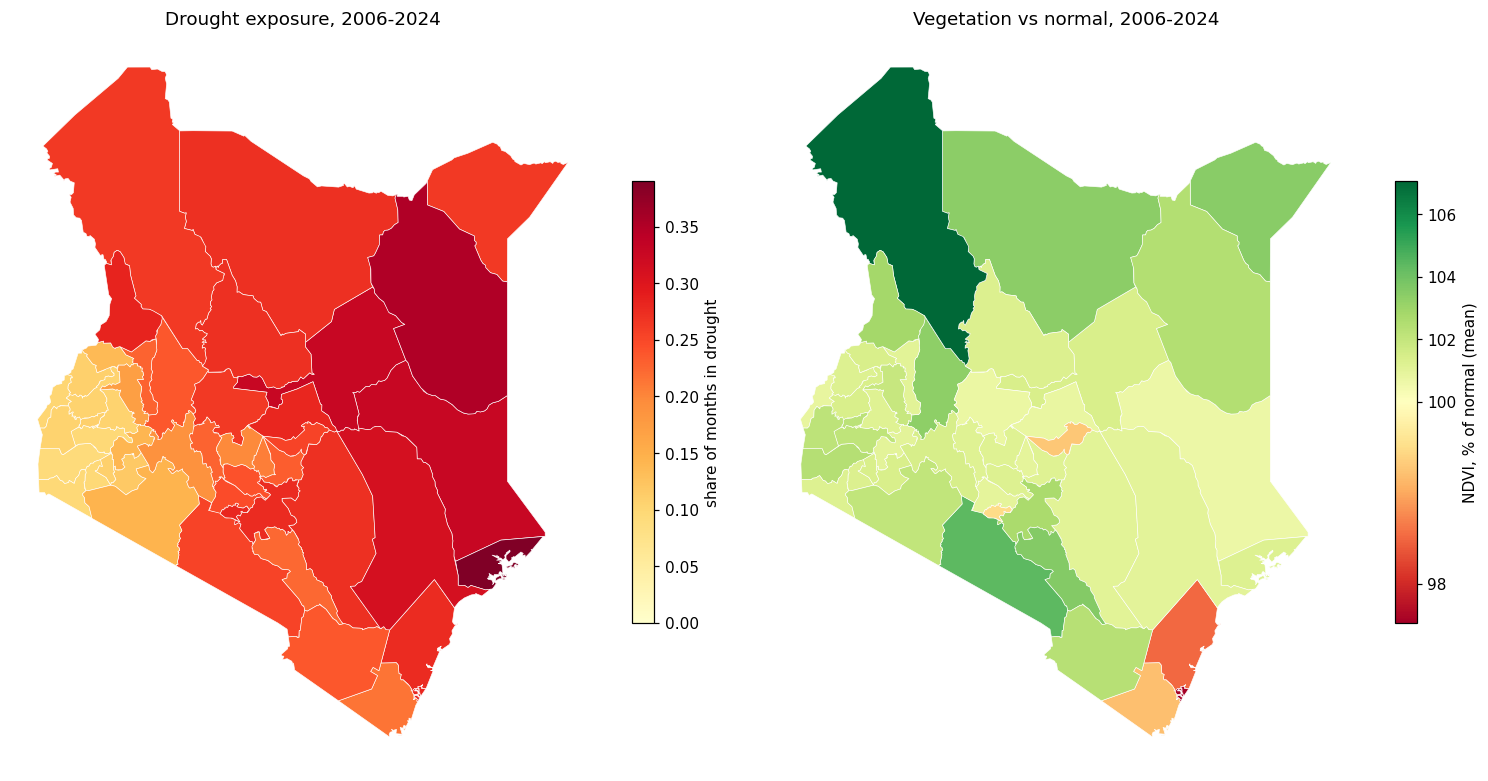

In [39]:
# Map 2: drought exposure 2006-2024 (share of months with 3-month rain < 75% of normal), observed for all counties
cm_ = cl_.assign(dr=cl_.rain_3m_pct < 75).groupby('county_pcode').dr.mean().to_dict()
fig, axs = plt.subplots(1, 2, figsize=(14, 7))
draw_map(axs[0], cm_, plt.cm.YlOrRd, mcolors.Normalize(0, max(cm_.values())), label='share of months in drought')
axs[0].set_title('Drought exposure, 2006-2024')
ndv = cl_.groupby('county_pcode').ndvi_pct.mean().to_dict()
draw_map(axs[1], ndv, plt.cm.RdYlGn, mcolors.TwoSlopeNorm(100, min(ndv.values()), max(ndv.values())), label='NDVI, % of normal (mean)')
axs[1].set_title('Vegetation vs normal, 2006-2024'); plt.tight_layout(); save('c18_map_drought_ndvi.png'); plt.show()

**What it shows:** Left: share of months each county spent in drought, 2006 to 2024. Right: average vegetation (NDVI) compared with normal.

**Insight:** The east and northeast, plus the coast, spend the most months in drought (up to about a third of months). The west around Lake Victoria rarely does. Average vegetation stays close to normal everywhere, because NDVI is measured against each county's own normal.

**What it means for SokoRadar:** The counties most exposed to drought are largely the same ones with the dearest maize. That overlap is where SokoRadar alerts can add the most value.

## 12. Findings to carry into the report

In [40]:
print('1. Real share of national train prices (independent core set):', round(float(REAL.loc[tr,CORE].values.mean()),2), '| MoA-only share:', round(float(REAL_MOA.loc[tr,CORE].values.mean()),2), '| estimated share:', round(1-float(REAL.loc[tr,CORE].values.mean()),2))
print('2. Independent series in the modelling set:', CORE, '| collapsed duplicates:', DUPES)
print('3. Kept as [EST]-only (too estimated or stale to fit models):', [c for c in names if c not in CAND])
print('4. Naive log-MAE, maize, [EST] h1/h2/h3:', B.loc['Dry Maize',['naive h1','naive h2','naive h3']].tolist(), '| [REAL]:', B.loc['Dry Maize',['naive h1 (real ends)','naive h2 (real ends)','naive h3 (real ends)']].tolist())
print('5. Dry-spell effect (pp, 3-month maize rise): [EST]', round(o_est['diff_pp'],1), '(HAC p %.3f)' % o_est['HAC_p'], '| [REAL]', round(o_real['diff_pp'],1), '(HAC p %.3f)' % o_real['HAC_p'])
print('6. Driver tests surviving Holm: [EST]', int((res_est.p_holm<.05).sum()), '| [REAL]', int((res_real.p_holm<.05).sum()), 'of', len(res_real))
print('7. Lead-lag tests surviving Holm: [EST]', int((LL_est.p_holm<.05).sum()), '| [REAL]', int((LL_real.p_holm<.05).sum()), 'of', len(LL_real))
print('8. WFP county series with 36+ months and 24+ run:', int(inv.long_enough.sum()), 'of', len(inv), '| also alive in test:', int(inv.model_ready.sum()), '| aggregate rows included:', INCLUDE_AGGREGATE)
print('9. The national reference prices for 2023-24 are entirely estimated; WFP county markets still have real prices in those years (%d market-crop-months).' % len(l2324))

1. Real share of national train prices (independent core set): 0.82 | MoA-only share: 0.14 | estimated share: 0.18
2. Independent series in the modelling set: ['Dry Maize', 'Sorghum', 'Beans Rosecoco', 'Red Irish Potatoes'] | collapsed duplicates: {'Beans Mwitemania': 'Beans Rosecoco', 'White Irish Potatoes': 'Red Irish Potatoes', 'Mwezi Moja': 'Beans Rosecoco', 'Beans Dolichos (Njahi)': 'Beans Rosecoco', 'Beans Canadian': 'Beans Rosecoco'}
3. Kept as [EST]-only (too estimated or stale to fit models): ['Wheat', 'Wheat flour', 'Beef', 'Goat meat', 'Eggs (KES/tray)', 'Milk (pasteurized)', 'Fish (omena, dried)', 'Vegetable oil']
4. Naive log-MAE, maize, [EST] h1/h2/h3: [0.062, 0.101, 0.13] | [REAL]: [0.056, 0.092, 0.121]
5. Dry-spell effect (pp, 3-month maize rise): [EST] 15.2 (HAC p 0.000) | [REAL] 15.1 (HAC p 0.000)
6. Driver tests surviving Holm: [EST] 3 | [REAL] 4 of 60
7. Lead-lag tests surviving Holm: [EST] 5 | [REAL] 3 of 36
8. WFP county series with 36+ months and 24+ run: 42 of 5

## 13. Export for the modelling notebook

In [41]:
import json
OUT = HANDOFF                                              
P.to_csv(OUT/'national_prices.csv')                       # index = month
REAL.to_csv(OUT/'national_real_flag.csv')                 # True = real (MoA observed, WFP scaled or WFP direct); False = estimated
REAL_MOA.to_csv(OUT/'national_moa_flag.csv')              # True = MoA observed only
THIN.to_csv(OUT/'national_thin_flag.csv')
K.to_csv(OUT/'national_kind.csv')
led.to_csv(OUT/'real_ledger.csv', index=False)            # WFP county rows, KES/kg, 2006-2026, with a `flag` column (actual / aggregate)
led_act.to_csv(OUT/'real_ledger_actual_only.csv', index=False)   # sensitivity: priceflag actual only
json.dump({'CORE': CORE, 'CAND': CAND, 'DUPES': DUPES, 'TRAIN': TRAIN, 'TEST': TEST, 'INCLUDE_AGGREGATE': INCLUDE_AGGREGATE}, open(OUT/'meta.json', 'w'))
print('saved to', OUT.resolve())

saved to C:\Users\dwtha\CAPSTONE2\handoff
